# Лабораторная работа №3
## Классификация временных рядов и прогноз температуры по шести городам

По почасовой погоде шести городов за 2019-2025 годы сначала определяем тип климата по месячному куску ряда, а затем прогнозируем температуру на каждый день следующего месяца.

Данные лежат в папке `data`, по одному файлу на город и год.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, RidgeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_white
from statsmodels.tsa.stattools import acf, adfuller

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["axes.unicode_minus"] = False

data_dir = Path("data")
if not list(data_dir.glob("*.parquet")):
    data_dir = Path("../data")

CITIES = [
    "Москва",
    "Санкт-Петербург",
    "Сочи",
    "Геленджик",
    "Благовещенск",
    "Находка",
]
CLIMATE = {
    "Москва": "умеренный",
    "Санкт-Петербург": "умеренный",
    "Сочи": "черноморский",
    "Геленджик": "черноморский",
    "Благовещенск": "дальневосточный",
    "Находка": "дальневосточный",
}
CLIM_ORDER = ["умеренный", "черноморский", "дальневосточный"]
# давление в классификатор не берём, его средний уровень повторяет высоту станции
CHANNELS = ["temp", "hum", "prec", "wind", "wind_max"]
WINDOW = 30
STRIDE = 7
RNG = np.random.default_rng(0)


In [2]:
# собираем сутки из часов, почасовой файл на город и год
gap_rows = []
daily_parts = []
hour_sample = None
hour_rows = []
for path in sorted(data_dir.glob("*.parquet")):
    city = path.stem.split("_")[0]
    raw = pd.read_parquet(path)
    raw.index = pd.to_datetime(raw.index)
    raw = raw.sort_index()
    # если час записан дважды, оставляем последнюю строку
    raw = raw[~raw.index.duplicated(keep="last")]
    full = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
    gap_rows.append({
        "город": city,
        "год": int(raw.index.year.min()),
        "часы": int(len(raw)),
        "пропущенные часы": int(len(full) - len(raw)),
        "макс доля пустых": float(raw.isna().mean().max()),
    })
    # температуру, влажность, ветер и давление усредняем, осадки суммируем
    day = pd.DataFrame({
        "temp": raw["temperature_2m"].resample("D").mean(),
        "tmin": raw["temperature_2m"].resample("D").min(),
        "tmax": raw["temperature_2m"].resample("D").max(),
        "hum": raw["relative_humidity_2m"].resample("D").mean(),
        "prec": raw["precipitation"].resample("D").sum(),
        "rain": raw["rain"].resample("D").sum(),
        "snow": raw["snowfall"].resample("D").sum(),
        "wind": raw["wind_speed_10m"].resample("D").mean(),
        "wind_max": raw["wind_speed_10m"].resample("D").max(),
        "press": raw["surface_pressure"].resample("D").mean(),
    })
    day["trange"] = day["tmax"] - day["tmin"]
    # проекция часового хода на синус и косинус часа, уровень дня вычитаем
    day_key = raw.index.floor("D")
    temp_h = raw["temperature_2m"].astype(float)
    anom_h = temp_h - temp_h.groupby(day_key).transform("mean")
    sin_h = np.sin(2 * np.pi * raw.index.hour / 24)
    cos_h = np.cos(2 * np.pi * raw.index.hour / 24)
    day["diurnal_sin"] = (anom_h * sin_h).groupby(day_key).mean()
    day["diurnal_cos"] = (anom_h * cos_h).groupby(day_key).mean()
    day["city"] = city
    day["climate"] = CLIMATE[city]
    daily_parts.append(day)
    hour_rows.append(pd.DataFrame({
        "city": city,
        "hour": raw.index.hour,
        "temp": temp_h.to_numpy(),
    }))
    if city == "Москва" and int(raw.index.year.min()) == 2019:
        hour_sample = raw.loc["2019-07-01":"2019-07-07", "temperature_2m"]

daily = pd.concat(daily_parts)
gaps = pd.DataFrame(gap_rows)
summary = (
    gaps.groupby("город", sort=False)
    .agg(
        часы=("часы", "sum"),
        пропущенные_часы=("пропущенные часы", "sum"),
        макс_доля_пустых=("макс доля пустых", "max"),
    )
    .reindex(CITIES)
    .reset_index()
)
print("годы", int(gaps["год"].min()), int(gaps["год"].max()), "городов", gaps["город"].nunique())
print(summary.round(3).to_string(index=False))
print("суток на город", int(daily.groupby("city").size().min()))
hour_all = pd.concat(hour_rows, ignore_index=True)


годы 2019 2025 городов 6
          город  часы  пропущенные_часы  макс_доля_пустых
         Москва 61368                 0               0.0
Санкт-Петербург 61368                 0               0.0
           Сочи 61368                 0               0.0
      Геленджик 61368                 0               0.0
   Благовещенск 61368                 0               0.0
        Находка 61368                 0               0.0
суток на город 2557


Повторных меток и пропущенных часов нет, у каждого города 61368 часов, или 2557 суток.


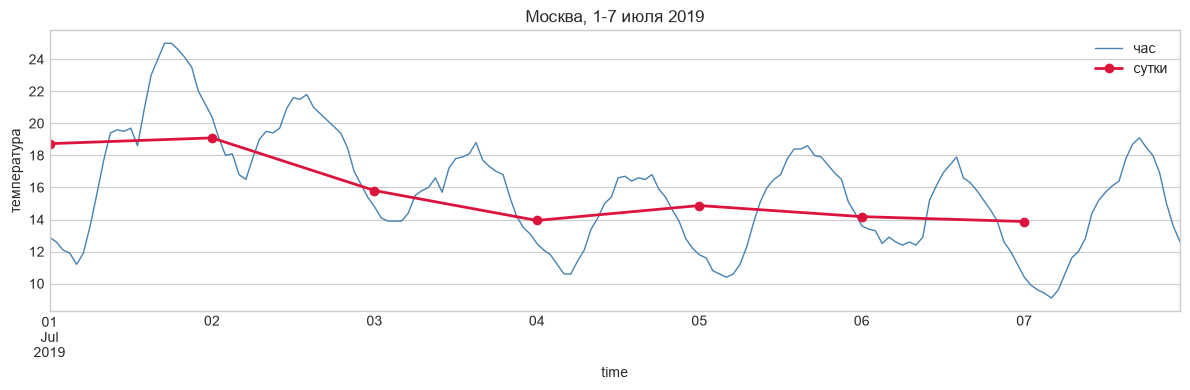

          город  средний суточный размах
         Москва                     7.35
Санкт-Петербург                     6.27
           Сочи                     6.78
      Геленджик                     7.01
   Благовещенск                     9.77
        Находка                     8.68


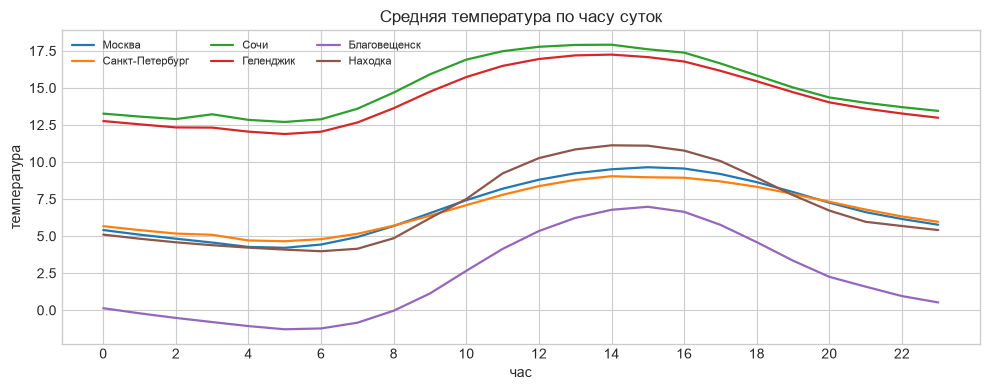

          город  размах среднего по часу
         Москва                     5.44
Санкт-Петербург                     4.39
           Сочи                     5.21
      Геленджик                     5.36
   Благовещенск                     8.27
        Находка                     7.15


In [3]:
# неделя июля, на ней виден суточный ход
week = hour_sample.copy()
fig, ax = plt.subplots(figsize=(12, 4))
week.plot(ax=ax, color="steelblue", linewidth=1.0, label="час")
week.resample("D").mean().plot(ax=ax, color="crimson", linewidth=2.0, marker="o", label="сутки")
ax.set_title("Москва, 1-7 июля 2019")
ax.set_ylabel("температура")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

trange = (
    daily.groupby("city")["trange"].mean()
    .reindex(CITIES)
    .round(2)
    .rename("средний суточный размах")
    .rename_axis("город")
    .reset_index()
)
print(trange.to_string(index=False))

profile = (
    hour_all.groupby(["city", "hour"])["temp"].mean()
    .unstack(0)
    .reindex(columns=CITIES)
)
fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, linewidth=1.6)
ax.set_title("Средняя температура по часу суток")
ax.set_xlabel("час")
ax.set_ylabel("температура")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc="upper left", ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

hour_span = (profile.max() - profile.min()).astype(float).round(2)
hour_tbl = hour_span.rename("размах среднего по часу").rename_axis("город").reset_index()
print(hour_tbl.to_string(index=False))


За сутки температура заметно меняется, средний размах дня от 6.27 в Санкт-Петербурге до 9.77 в Благовещенске. Теплее всего у всех городов в 14-15 часов, холоднее всего в 5-6 утра, так что форма суточного хода общая и климат по ней не различить. Поэтому дальше работаем с сутками, температуру, влажность, ветер и давление усредняем, а осадки суммируем. Размах дня и проекцию суточного хода на синус и косинус часа сохраняем в признаках, чтобы амплитуда суток не потерялась.

Пропусков в данных нет. Если бы они были, короткие дыры в несколько часов мы закрыли бы линейной интерполяцией по времени, потому что температура и давление меняются плавно, а длинные простои оставили бы пустыми. Сильные морозы и жару не убираем, для метеоцентра это и есть опасные явления.


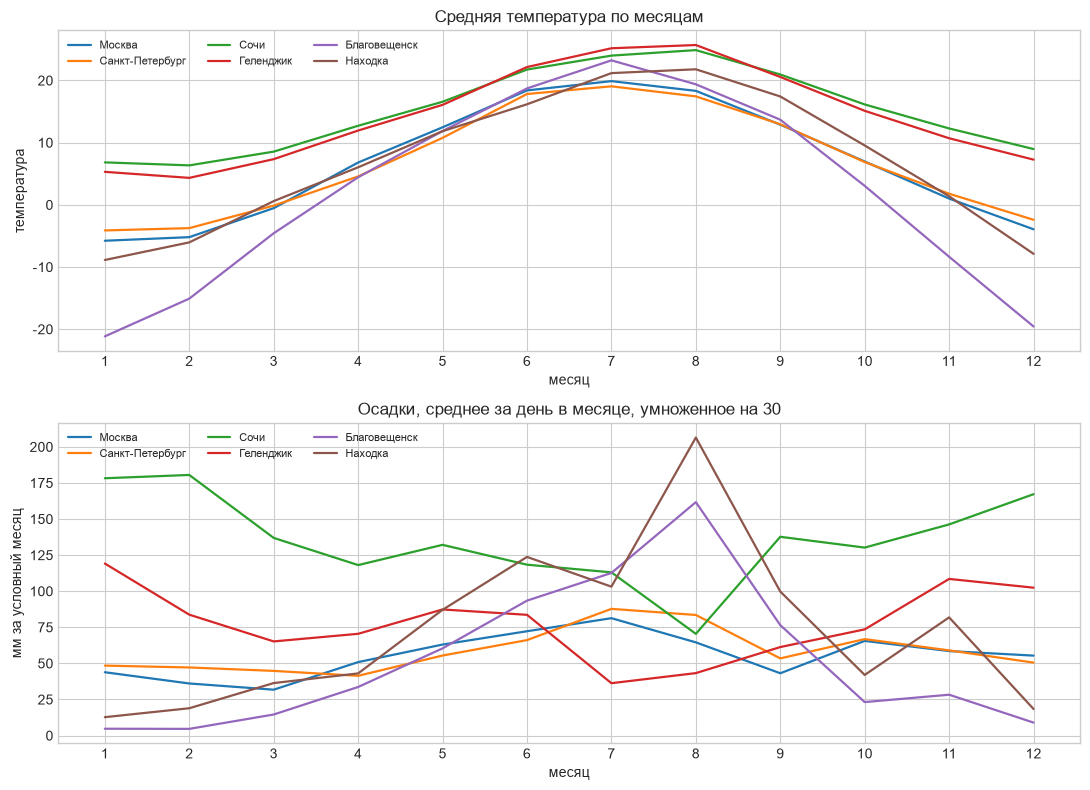

температура, январь и июль
time                1     7
city                       
Москва           -5.8  19.9
Санкт-Петербург  -4.1  19.1
Сочи              6.8  24.0
Геленджик         5.3  25.2
Благовещенск    -21.2  23.2
Находка          -8.9  21.2
размах год
          город  июль минус январь
         Москва               25.7
Санкт-Петербург               23.2
           Сочи               17.2
      Геленджик               19.9
   Благовещенск               44.4
        Находка               30.1
сумма за все годы
          город  снег  осадки  доля снега
         Москва 882.0  4745.0       0.186
Санкт-Петербург 818.0  5014.0       0.163
           Сочи 354.0 11548.0       0.031
      Геленджик 236.0  6634.0       0.036
   Благовещенск 373.0  4447.0       0.084
        Находка 325.0  6225.0       0.052


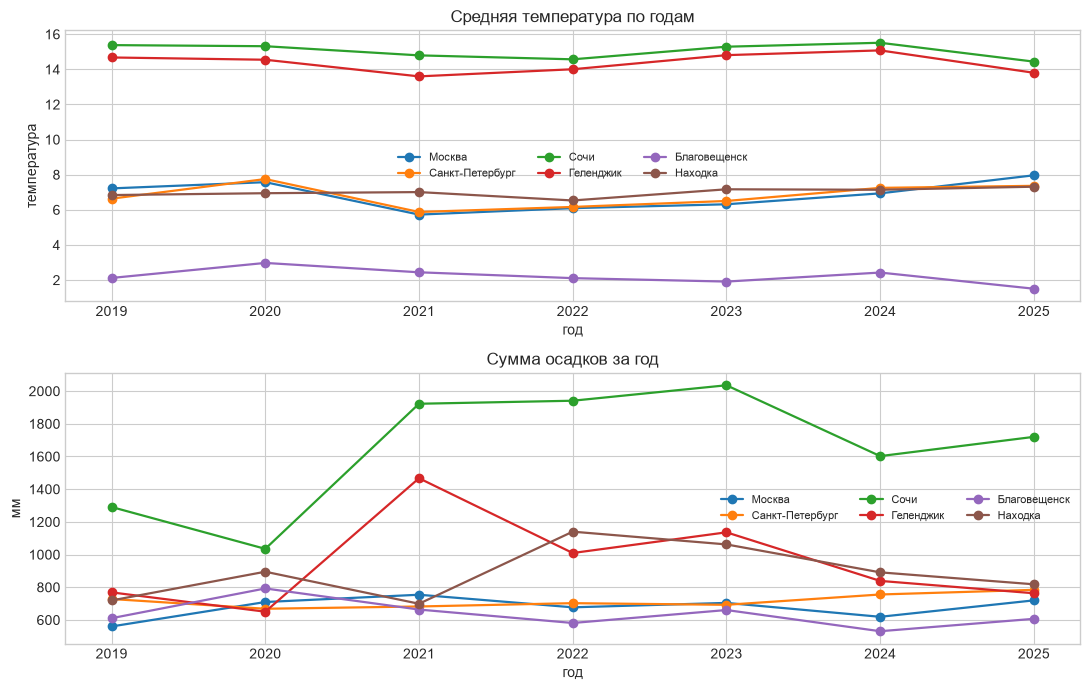

температура по годам
city  Москва  Санкт-Петербург   Сочи  Геленджик  Благовещенск  Находка
time                                                                  
2019    7.22             6.63  15.38      14.68          2.12     6.84
2020    7.57             7.75  15.32      14.55          2.97     6.94
2021    5.73             5.87  14.80      13.60          2.44     7.01
2022    6.09             6.16  14.57      14.01          2.11     6.53
2023    6.31             6.50  15.29      14.81          1.91     7.17
2024    6.94             7.25  15.51      15.08          2.42     7.14
2025    7.96             7.36  14.44      13.80          1.50     7.31
осадки по годам
city  Москва  Санкт-Петербург    Сочи  Геленджик  Благовещенск  Находка
time                                                                   
2019   560.0            728.0  1291.0      769.0         611.0    719.0
2020   710.0            668.0  1035.0      650.0         793.0    895.0
2021   754.0            682.0  1923.

In [4]:
# среднемесячный ход температуры и осадков
month_temp = (
    daily.groupby(["city", daily.index.month])["temp"].mean()
    .unstack(0)
    .reindex(columns=CITIES)
)
month_prec = (
    daily.groupby(["city", daily.index.month])["prec"].mean()
    .unstack(0)
    .reindex(columns=CITIES)
    * 30  # среднее за день переводим в сумму условного месяца
)
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
month_temp.plot(ax=axes[0], linewidth=1.6)
axes[0].set_title("Средняя температура по месяцам")
axes[0].set_xlabel("месяц")
axes[0].set_ylabel("температура")
axes[0].set_xticks(range(1, 13))
axes[0].legend(loc="upper left", ncol=3, fontsize=8)
month_prec.plot(ax=axes[1], linewidth=1.6)
axes[1].set_title("Осадки, среднее за день в месяце, умноженное на 30")
axes[1].set_xlabel("месяц")
axes[1].set_ylabel("мм за условный месяц")
axes[1].set_xticks(range(1, 13))
axes[1].legend(loc="upper left", ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

span = (month_temp.loc[7] - month_temp.loc[1]).astype(float).round(1)
span_tbl = span.rename("июль минус январь").rename_axis("город").reset_index()
print("температура, январь и июль")
print(month_temp.loc[[1, 7]].T.astype(float).round(1).to_string())
print("размах год")
print(span_tbl.to_string(index=False))
snow = (
    daily.groupby("city")[["snow", "prec"]].sum()
    .reindex(CITIES)
)
snow["доля снега"] = (snow["snow"] / snow["prec"]).round(3)
snow_tbl = snow.reset_index().rename(columns={"city": "город", "snow": "снег", "prec": "осадки"})
print("сумма за все годы")
snow_tbl["снег"] = snow_tbl["снег"].round(0)
snow_tbl["осадки"] = snow_tbl["осадки"].round(0)
snow_tbl["доля снега"] = snow_tbl["доля снега"].round(3)
print(snow_tbl.to_string(index=False))

year_temp = (
    daily.groupby(["city", daily.index.year])["temp"].mean()
    .unstack(0)
    .reindex(columns=CITIES)
)
year_prec = (
    daily.groupby(["city", daily.index.year])["prec"].sum()
    .unstack(0)
    .reindex(columns=CITIES)
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
year_temp.plot(ax=axes[0], linewidth=1.6, marker="o")
axes[0].set_title("Средняя температура по годам")
axes[0].set_xlabel("год")
axes[0].set_ylabel("температура")
axes[0].legend(loc="best", ncol=3, fontsize=8)
year_prec.plot(ax=axes[1], linewidth=1.6, marker="o")
axes[1].set_title("Сумма осадков за год")
axes[1].set_xlabel("год")
axes[1].set_ylabel("мм")
axes[1].legend(loc="best", ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
print("температура по годам")
print(year_temp.astype(float).round(2).to_string())
print("осадки по годам")
print(year_prec.astype(float).round(0).to_string())


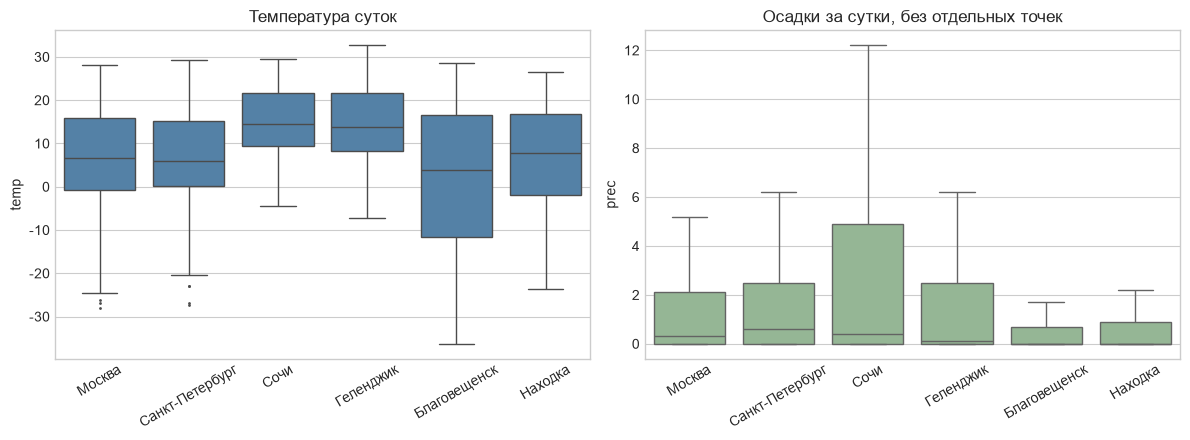

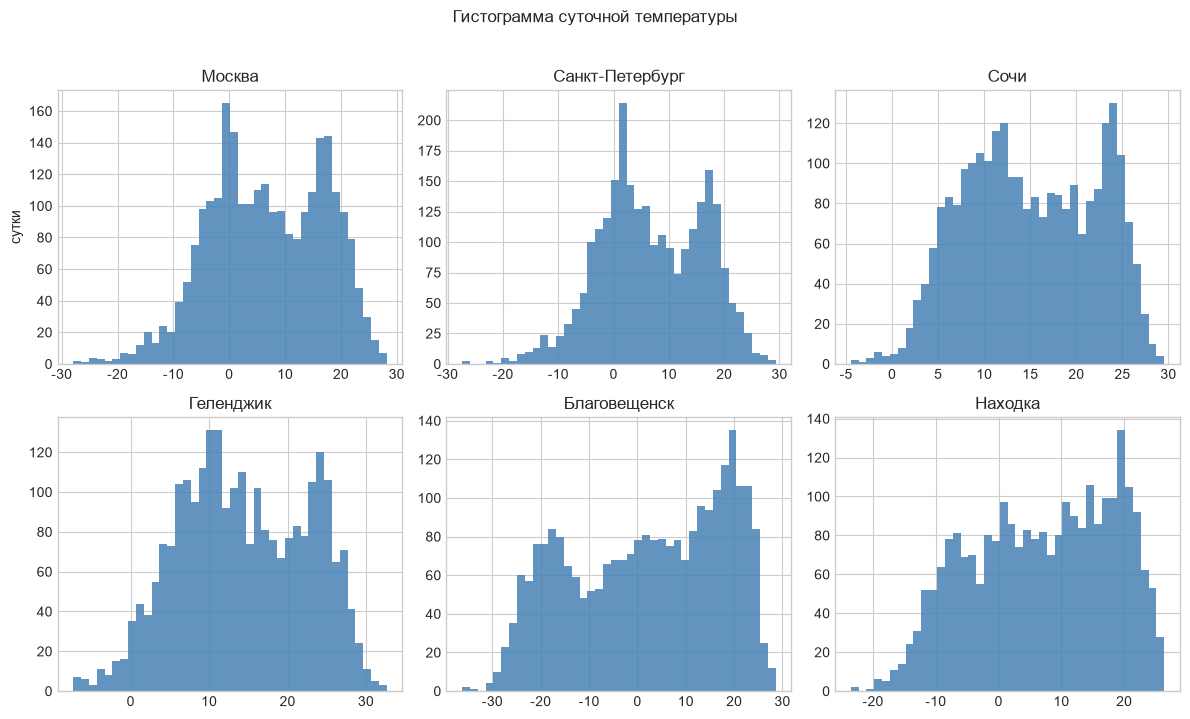

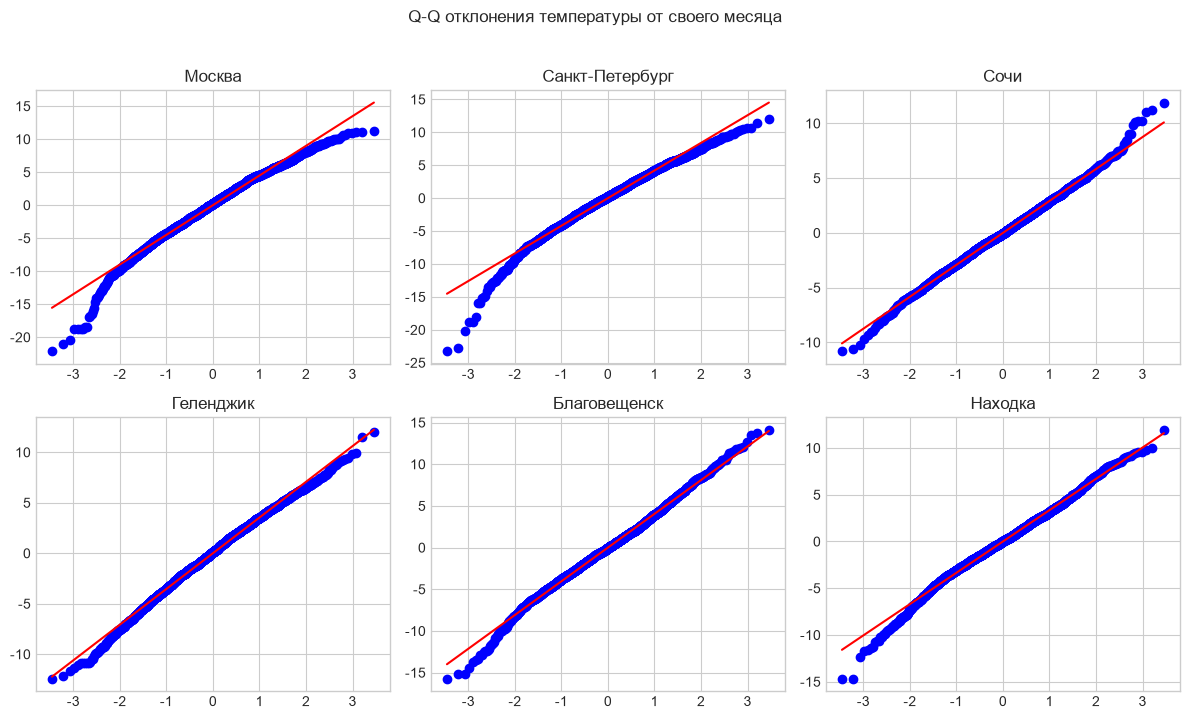

          город      признак  среднее   std    min     max
         Москва  температура     6.83 10.24 -27.94   28.22
         Москва    влажность    75.76 12.92  32.54   98.54
         Москва       осадки     1.86  3.64   0.00   38.20
         Москва        ветер    14.14  5.76   2.73   35.26
         Москва     давление   991.62  9.69 951.18 1027.34
         Москва размах суток     7.35  3.69   0.60   20.90
Санкт-Петербург  температура     6.79  9.34 -27.41   29.29
Санкт-Петербург    влажность    79.04 11.17  39.58   99.58
Санкт-Петербург       осадки     1.96  3.41   0.00   35.20
Санкт-Петербург        ветер    14.59  5.53   3.12   35.55
Санкт-Петербург     давление  1012.38 10.95 975.17 1053.10
Санкт-Петербург размах суток     6.27  3.27   0.30   18.10
           Сочи  температура    15.04  7.06  -4.48   29.55
           Сочи    влажность    77.85 10.12  39.46   96.75
           Сочи       осадки     4.52  8.66   0.00   93.40
           Сочи        ветер     8.84  4.03   2.73   32.

In [5]:
# распределения температуры и осадков, ящик и гистограмма
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=daily, x="city", y="temp", order=CITIES, ax=axes[0], color="steelblue", fliersize=1)
axes[0].set_title("Температура суток")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=daily, x="city", y="prec", order=CITIES, ax=axes[1], color="darkseagreen", fliersize=1, showfliers=False)
axes[1].set_title("Осадки за сутки, без отдельных точек")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, city in zip(axes.ravel(), CITIES):
    sample = daily.loc[daily["city"] == city, "temp"]
    ax.hist(sample, bins=40, color="steelblue", alpha=0.85)
    ax.set_title(city)
axes[0, 0].set_ylabel("сутки")
plt.suptitle("Гистограмма суточной температуры", y=1.02)
plt.tight_layout()
plt.show()

# Q-Q отклонения температуры от среднего своего месяца
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, city in zip(axes.ravel(), CITIES):
    part = daily.loc[daily["city"] == city, ["temp"]].copy()
    part["month"] = part.index.month
    center = part.groupby("month")["temp"].transform("mean")
    anom = (part["temp"] - center).dropna()
    stats.probplot(anom, dist="norm", plot=ax)
    ax.set_title(city)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Q-Q отклонения температуры от своего месяца", y=1.02)
plt.tight_layout()
plt.show()

desc_rows = []
for city in CITIES:
    part = daily.loc[daily["city"] == city]
    for col, title in [("temp", "температура"), ("hum", "влажность"), ("prec", "осадки"), ("wind", "ветер"), ("press", "давление"), ("trange", "размах суток")]:
        s = part[col]
        desc_rows.append({
            "город": city,
            "признак": title,
            "среднее": round(float(s.mean()), 2),
            "std": round(float(s.std()), 2),
            "min": round(float(s.min()), 2),
            "max": round(float(s.max()), 2),
        })
desc = pd.DataFrame(desc_rows)
print(desc.to_string(index=False))


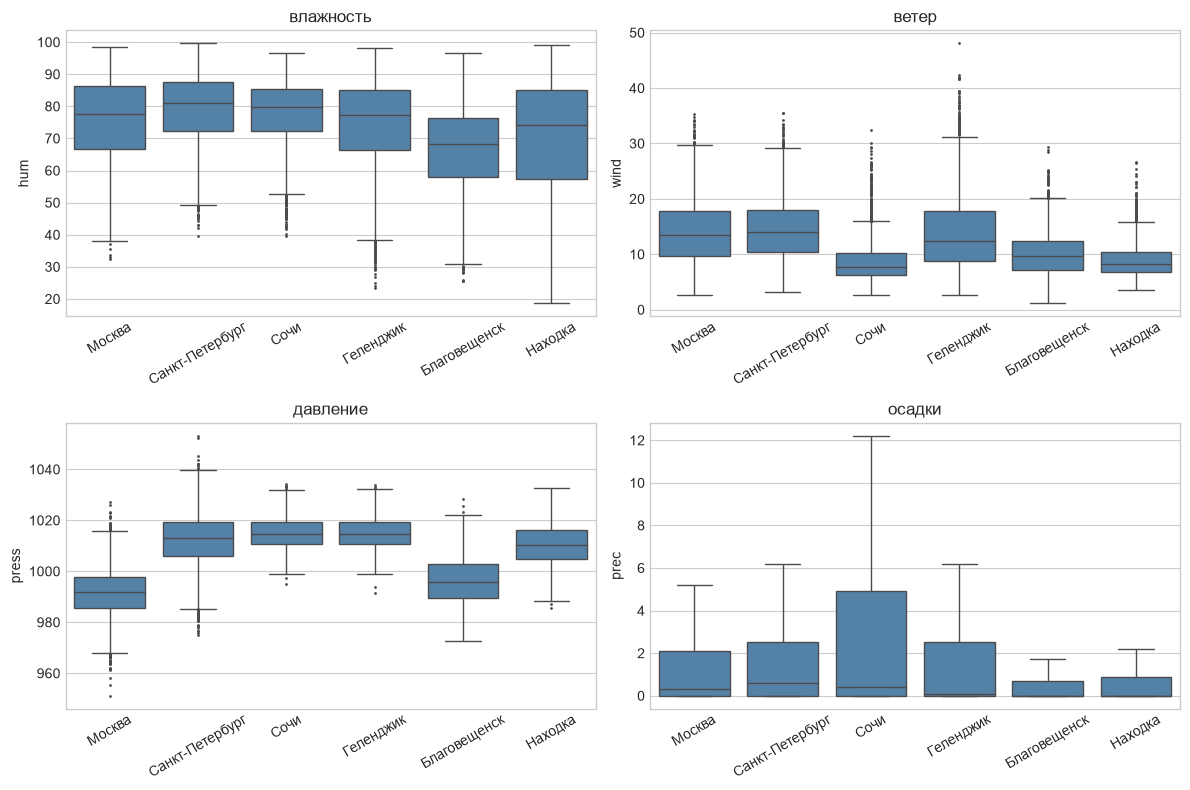

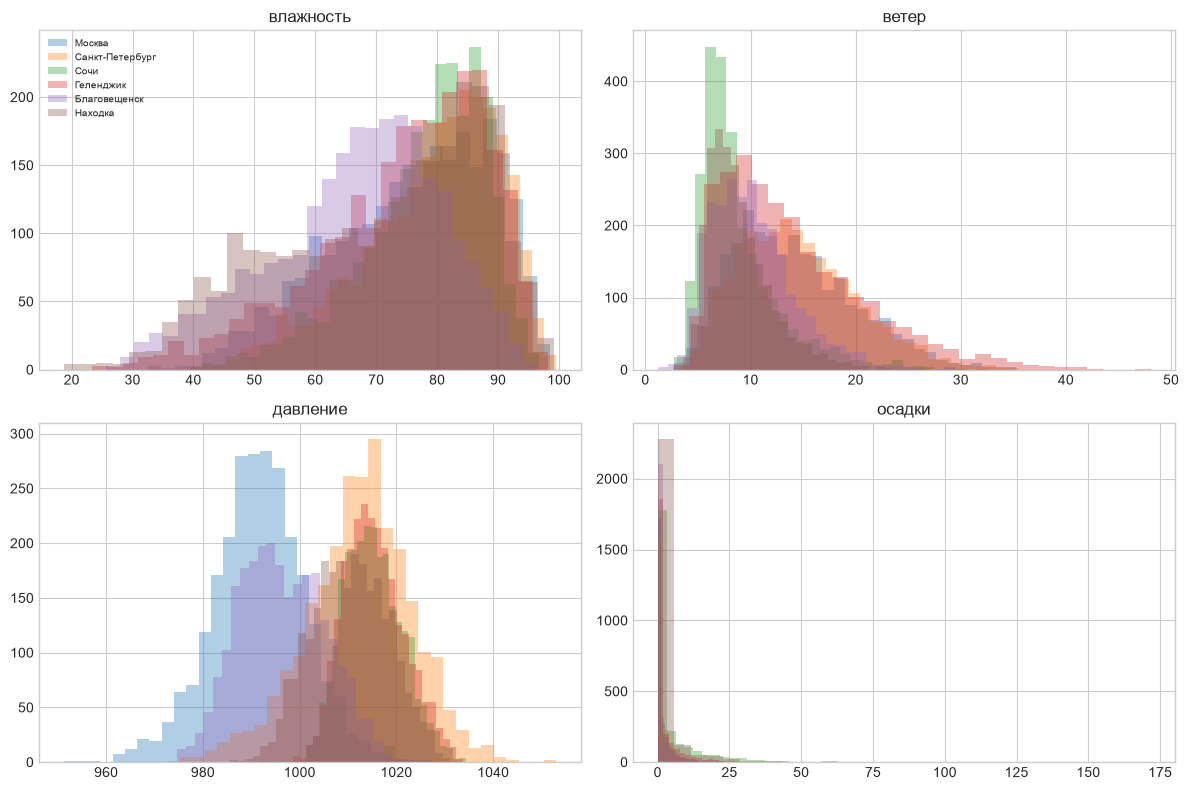

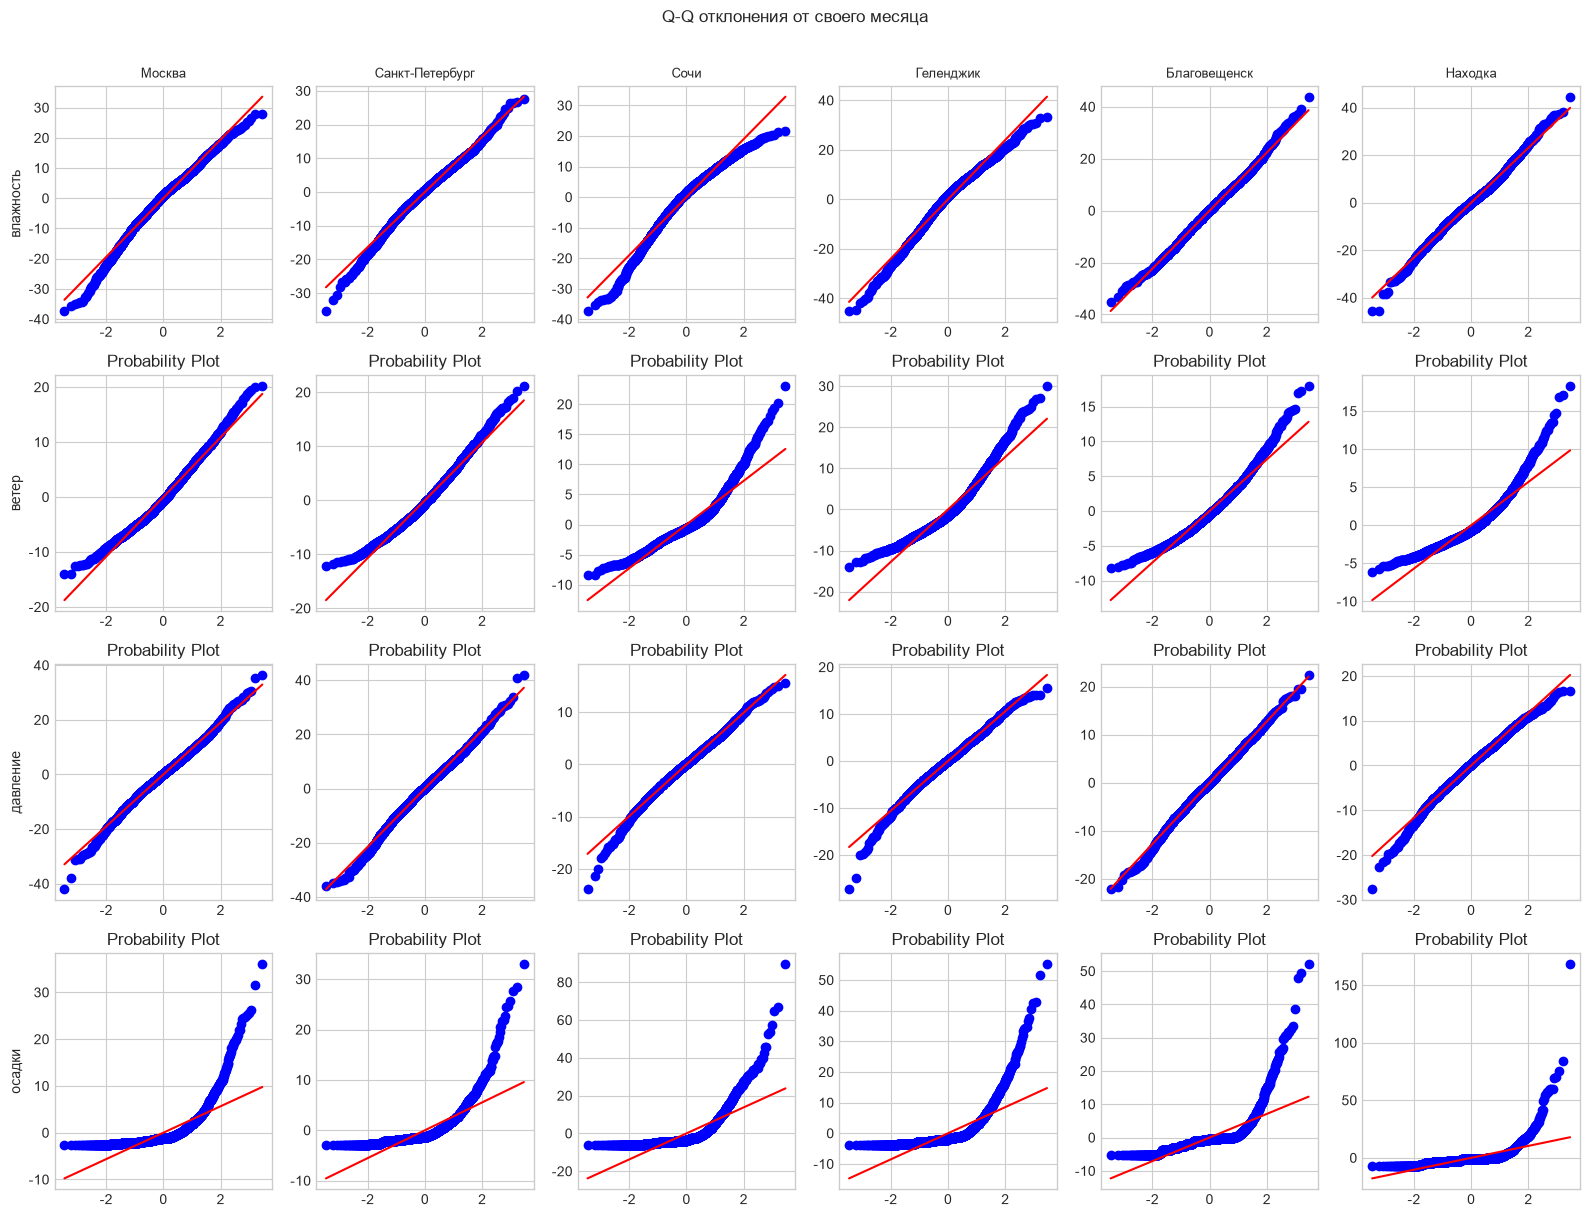

In [6]:
# ящик, гистограмма и Q-Q влажности, ветра, давления и осадков
extra = [("hum", "влажность"), ("wind", "ветер"), ("press", "давление"), ("prec", "осадки")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.ravel(), extra):
    sns.boxplot(
        data=daily, x="city", y=col, order=CITIES, ax=ax,
        color="steelblue", fliersize=1, showfliers=(col != "prec"),
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.ravel(), extra):
    for city in CITIES:
        sample = daily.loc[daily["city"] == city, col]
        ax.hist(sample, bins=30, alpha=0.35, label=city)
    ax.set_title(title)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 6, figsize=(16, 12))
for r, (col, title) in enumerate(extra):
    for c, city in enumerate(CITIES):
        ax = axes[r, c]
        part = daily.loc[daily["city"] == city, [col]].copy()
        part["month"] = part.index.month
        center = part.groupby("month")[col].transform("mean")
        anom = (part[col] - center).dropna()
        stats.probplot(anom, dist="norm", plot=ax)
        ax.set_xlabel("")
        ax.set_ylabel("")
        if r == 0:
            ax.set_title(city, fontsize=9)
        if c == 0:
            ax.set_ylabel(title)
plt.suptitle("Q-Q отклонения от своего месяца", y=1.01)
plt.tight_layout()
plt.show()


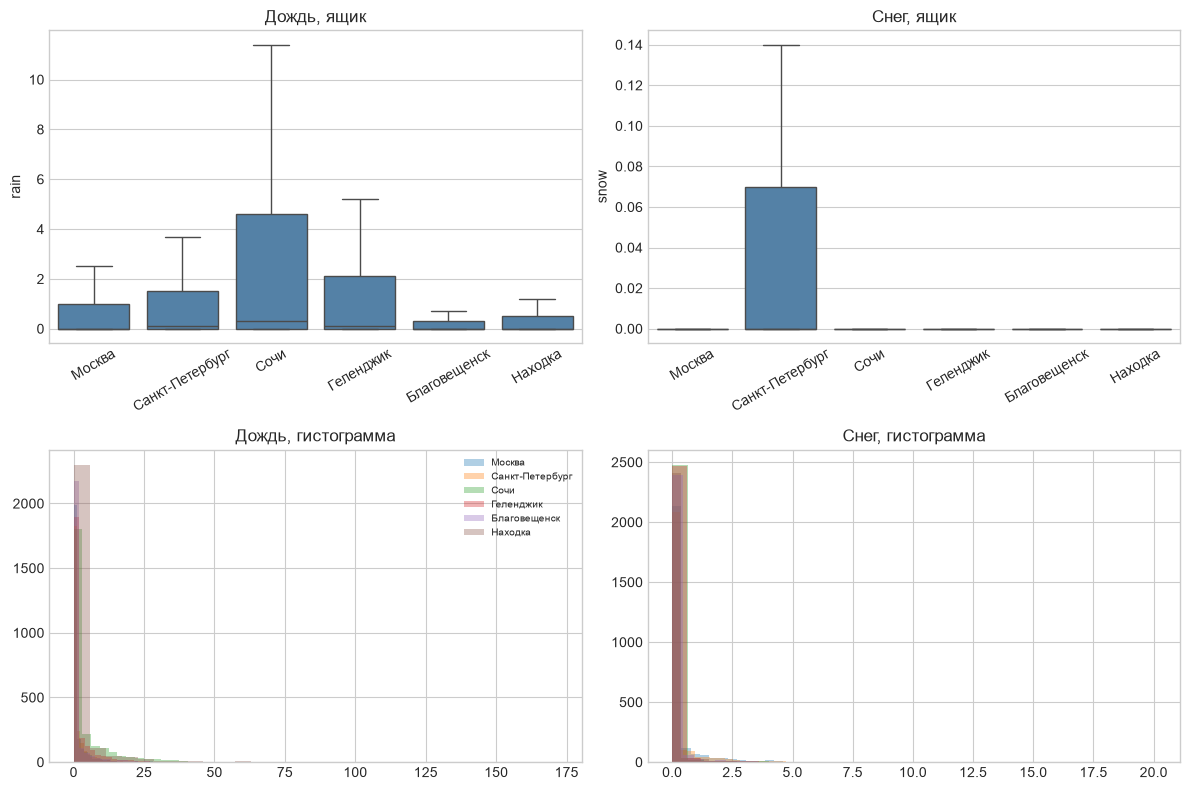

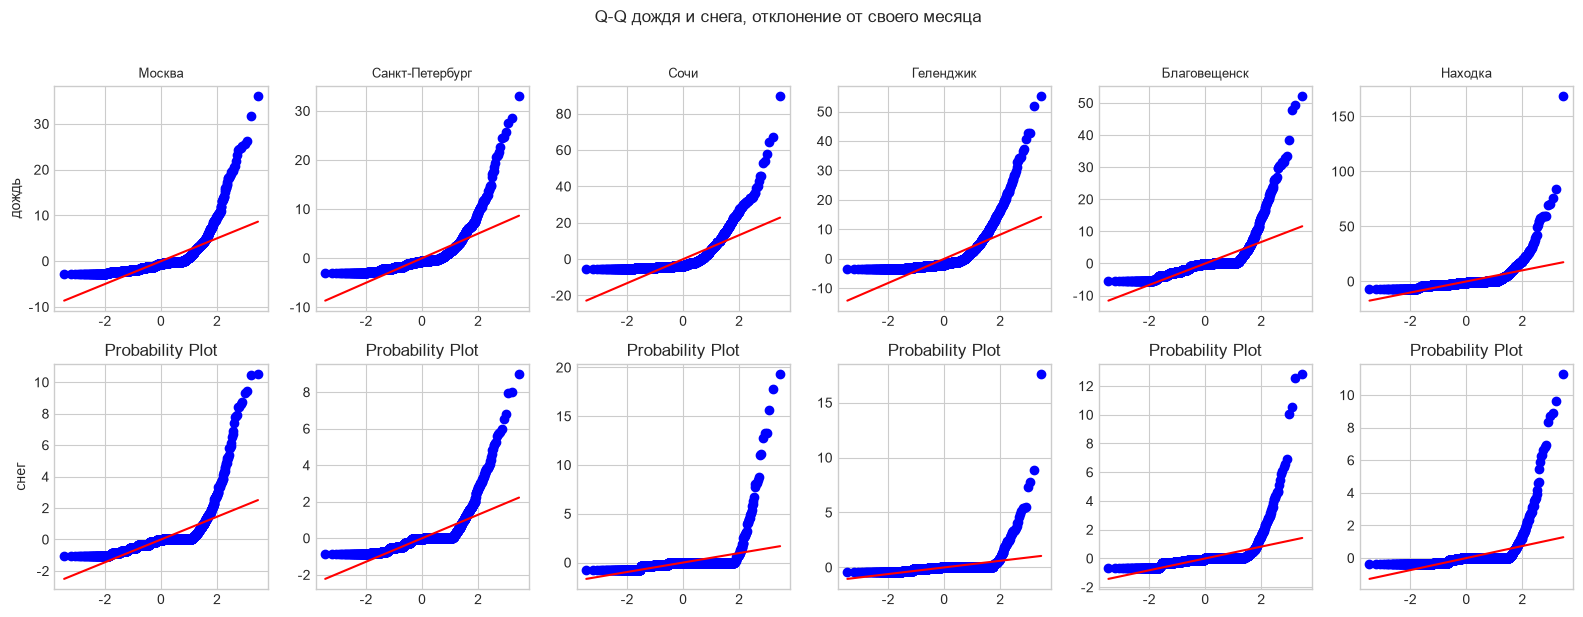

          город  доля суток без дождя  доля суток без снега  макс дождь  макс снег
         Москва                 0.526                 0.751        38.2       11.6
Санкт-Петербург                 0.473                 0.749        35.2        9.4
           Сочи                 0.429                 0.955        93.4       20.1
      Геленджик                 0.485                 0.940        58.0       18.0
   Благовещенск                 0.696                 0.870        57.5       13.4
        Находка                 0.640                 0.904       171.7       11.6
доля часов по группе кода погоды
          город  ясно  облака  дождь  снег
         Москва 0.200   0.613  0.114 0.073
Санкт-Петербург 0.193   0.602  0.135 0.070
           Сочи 0.341   0.437  0.210 0.013
      Геленджик 0.341   0.477  0.167 0.016
   Благовещенск 0.382   0.502  0.081 0.035
        Находка 0.386   0.494  0.098 0.022


In [7]:
# дождь и снег рисуем своими графиками, код погоды группируем по явлениям
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, title in (
    (axes[0, 0], "rain", "Дождь, ящик"),
    (axes[0, 1], "snow", "Снег, ящик"),
):
    sns.boxplot(data=daily, x="city", y=col, order=CITIES, ax=ax, color="steelblue", fliersize=1, showfliers=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
for ax, col, title in (
    (axes[1, 0], "rain", "Дождь, гистограмма"),
    (axes[1, 1], "snow", "Снег, гистограмма"),
):
    for city in CITIES:
        ax.hist(daily.loc[daily["city"] == city, col], bins=30, alpha=0.35, label=city)
    ax.set_title(title)
axes[1, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, (col, title) in enumerate((("rain", "дождь"), ("snow", "снег"))):
    for c, city in enumerate(CITIES):
        ax = axes[r, c]
        part = daily.loc[daily["city"] == city, [col]].copy()
        part["month"] = part.index.month
        center = part.groupby("month")[col].transform("mean")
        anom = (part[col] - center).dropna()
        stats.probplot(anom, dist="norm", plot=ax)
        ax.set_xlabel("")
        ax.set_ylabel("")
        if r == 0:
            ax.set_title(city, fontsize=9)
        if c == 0:
            ax.set_ylabel(title)
plt.suptitle("Q-Q дождя и снега, отклонение от своего месяца", y=1.02)
plt.tight_layout()
plt.show()

zero_rows = []
for city in CITIES:
    part = daily.loc[daily["city"] == city]
    zero_rows.append({
        "город": city,
        "доля суток без дождя": round(float((part["rain"] == 0).mean()), 3),
        "доля суток без снега": round(float((part["snow"] == 0).mean()), 3),
        "макс дождь": round(float(part["rain"].max()), 1),
        "макс снег": round(float(part["snow"].max()), 1),
    })
print(pd.DataFrame(zero_rows).to_string(index=False))

# группы по кодам WMO, дождь 51-67 и 80-82, снег 71-77 и 85-86
def weather_group(code):
    code = int(code)
    if code == 0:
        return "ясно"
    if code <= 3:
        return "облака"
    if code in (45, 48):
        return "туман"
    if 51 <= code <= 67 or 80 <= code <= 82:
        return "дождь"
    if 71 <= code <= 77 or code in (85, 86):
        return "снег"
    if code >= 95:
        return "гроза"
    return "другое"

by_city = {city: [] for city in CITIES}
for path in sorted(data_dir.glob("*.parquet")):
    city = path.stem.split("_")[0]
    raw = pd.read_parquet(path, columns=["weathercode"])
    by_city[city].append(raw["weathercode"].map(weather_group))
rows = []
for city in CITIES:
    groups = pd.concat(by_city[city], ignore_index=True)
    share = groups.value_counts(normalize=True)
    share["город"] = city
    rows.append(share)
code_tbl = pd.DataFrame(rows).fillna(0)
order = ["ясно", "облака", "туман", "дождь", "снег", "гроза", "другое"]
cols = ["город"] + [c for c in order if c in code_tbl.columns]
code_tbl = code_tbl.reindex(columns=cols).round(3)
print("доля часов по группе кода погоды")
print(code_tbl.to_string(index=False))


У дождя и снега много нулевых суток. Без дождя от 42.9% суток в Сочи до 69.6% в Благовещенске, без снега от 74.9% в Санкт-Петербурге до 95.5% в Сочи. Самый сильный дождь за сутки 171.7 мм в Находке, снег 20.1 мм в Сочи. Из-за нулей распределения сильно скошены и Q-Q уходит от прямой, но сухие сутки оставляем, это реальная погода.

Код погоды обозначает тип явления, поэтому вместо ящиков считаем долю часов по группам. В Сочи ясно 34.1% часов и дождь идёт 21.0%, в Москве ясных часов 20.0% и облачных 61.3%. Снег чаще всего в Москве и Санкт-Петербурге, 7.3% и 7.0% часов, а в Сочи только 1.3%.


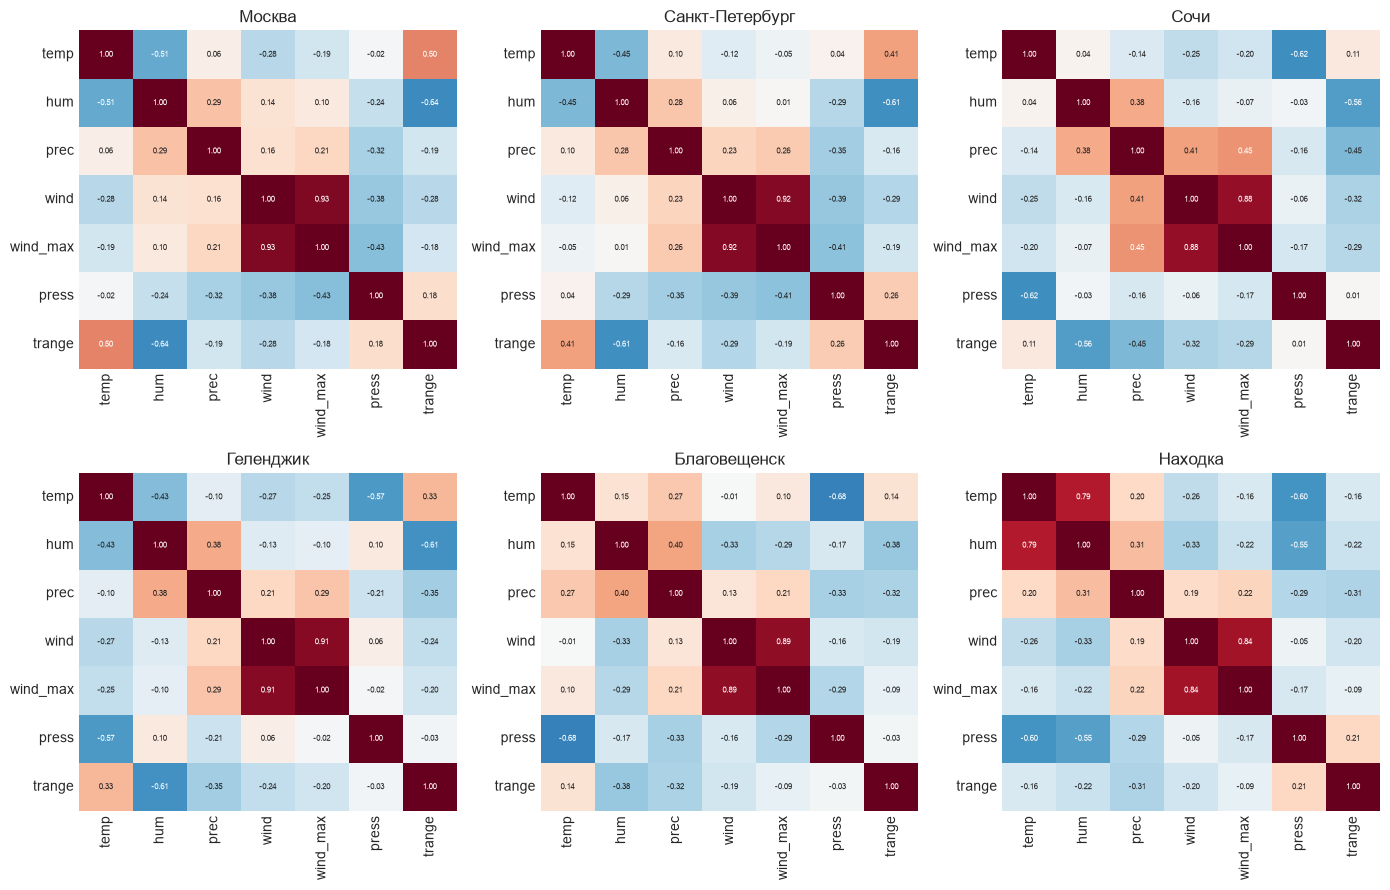

          город  temp и hum  temp и prec  temp и wind  temp и press  temp и wind_max
         Москва      -0.510        0.064       -0.276        -0.022           -0.192
Санкт-Петербург      -0.449        0.101       -0.119         0.041           -0.048
           Сочи       0.039       -0.144       -0.253        -0.623           -0.196
      Геленджик      -0.435       -0.104       -0.275        -0.572           -0.249
   Благовещенск       0.150        0.268       -0.008        -0.679            0.103
        Находка       0.790        0.200       -0.258        -0.596           -0.158


In [8]:
# связь всех суточных столбцов, тепловая карта по каждому городу
corr_cols = ["temp", "hum", "prec", "wind", "wind_max", "press", "trange"]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, city in zip(axes.ravel(), CITIES):
    corr = daily.loc[daily["city"] == city, corr_cols].corr()
    sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, vmin=-1, vmax=1, annot_kws={"size": 6}, cbar=False)
    ax.set_title(city)
plt.tight_layout()
plt.show()

rows = []
for city in CITIES:
    part = daily.loc[daily["city"] == city]
    rows.append({
        "город": city,
        "temp и hum": round(float(part["temp"].corr(part["hum"])), 3),
        "temp и prec": round(float(part["temp"].corr(part["prec"])), 3),
        "temp и wind": round(float(part["temp"].corr(part["wind"])), 3),
        "temp и press": round(float(part["temp"].corr(part["press"])), 3),
        "temp и wind_max": round(float(part["temp"].corr(part["wind_max"])), 3),
    })
print(pd.DataFrame(rows).to_string(index=False))


In [9]:
# стационарность суточной температуры, уровень и первая разность
adf_rows = []
for city in CITIES:
    y = daily.loc[daily["city"] == city, "temp"].dropna()
    level = adfuller(y, autolag="AIC", result_object=False)
    diff = adfuller(y.diff().dropna(), autolag="AIC", result_object=False)
    adf_rows.append({
        "город": city,
        "ADF p, уровень": f"{float(level[1]):.4f}" if level[1] >= 1e-4 else "<0.0001",
        "ADF p, разность": f"{float(diff[1]):.4f}" if diff[1] >= 1e-4 else "<0.0001",
    })
print(pd.DataFrame(adf_rows).to_string(index=False))

# хвосты считаем относительно своего месяца и оставляем в ряде
tail_rows = []
for city in CITIES:
    part = daily.loc[daily["city"] == city, ["temp"]].copy()
    part["month"] = part.index.month
    mu = part.groupby("month")["temp"].transform("mean")
    sd = part.groupby("month")["temp"].transform("std")
    z = (part["temp"] - mu) / sd
    tail_rows.append({
        "город": city,
        "сутки |z| > 3": int((z.abs() > 3).sum()),
        "минимум": round(float(part["temp"].min()), 1),
        "максимум": round(float(part["temp"].max()), 1),
    })
print("края температуры")
print(pd.DataFrame(tail_rows).to_string(index=False))


          город ADF p, уровень ADF p, разность
         Москва         0.0225         <0.0001
Санкт-Петербург         0.0210         <0.0001
           Сочи         0.0267         <0.0001
      Геленджик         0.0339         <0.0001
   Благовещенск         0.0135         <0.0001
        Находка         0.0519         <0.0001
края температуры
          город  сутки |z| > 3  минимум  максимум
         Москва              7    -27.9      28.2
Санкт-Петербург             10    -27.4      29.3
           Сочи              8     -4.5      29.6
      Геленджик              3     -7.3      32.7
   Благовещенск             10    -36.3      28.6
        Находка              6    -23.5      26.4


В январе города делятся на три пары. На черноморском побережье тепло, 6.8 в Сочи и 5.3 в Геленджике, в Москве и Санкт-Петербурге слабый мороз, -5.8 и -4.1, а на Дальнем Востоке холоднее всего, -8.9 в Находке и -21.2 в Благовещенске. Летом разница меньше, от 19.1 до 25.2, поэтому годовой размах сильно отличается, 44.4 в Благовещенске и 17.2 в Сочи. По этим парам задаём тип климата, умеренный для Москвы и Санкт-Петербурга, черноморский для Сочи и Геленджика и дальневосточный для Благовещенска и Находки.

Между годами средняя температура меняется слабее, чем внутри года, у Москвы от 5.73 в 2021 до 7.96 в 2025. Больше всего осадков в Сочи, 11548 мм за семь лет против 4745 мм в Москве, и там же самый большой разброс по годам, от 1035 мм в 2020 до 2036 мм в 2023. Доля снега в осадках выше в Москве и Санкт-Петербурге, 0.186 и 0.163, а в Сочи она 0.031.

Нормально не распределён ни один показатель. Сырая температура двугорбая из-за зимы и лета, а у отклонений от своего месяца хвосты тяжелее нормальных, как и у влажности, ветра, давления и осадков. Суток с модулем z больше 3 немного, от 3 в Геленджике до 10 в Санкт-Петербурге и Благовещенске, и мы их оставляем.

Связь температуры с влажностью зависит от климата, в Москве она отрицательная, -0.510, а в Находке положительная, +0.790, потому что лето там приносит влажный муссон. С давлением температура заметно связана у Сочи, Геленджика, Благовещенска и Находки, от -0.572 до -0.679, а у Москвы и Санкт-Петербурга связи почти нет.

ADF отвергает единичный корень у пяти городов на уровне 0.05, у Находки p 0.0519, а после первой разности p везде ниже 0.0001. Сам ряд при этом держится около своего сезона, поэтому для прогноза вычитаем норму календарного дня и дальше работаем с отклонением от неё.


          город  лаг 1  лаг 7  лаг 30  лаг 365
         Москва  0.969  0.850   0.714    0.724
Санкт-Петербург  0.967  0.840   0.710    0.718
           Сочи  0.969  0.863   0.708    0.722
      Геленджик  0.961  0.840   0.691    0.705
   Благовещенск  0.986  0.942   0.796    0.813
        Находка  0.976  0.919   0.779    0.801


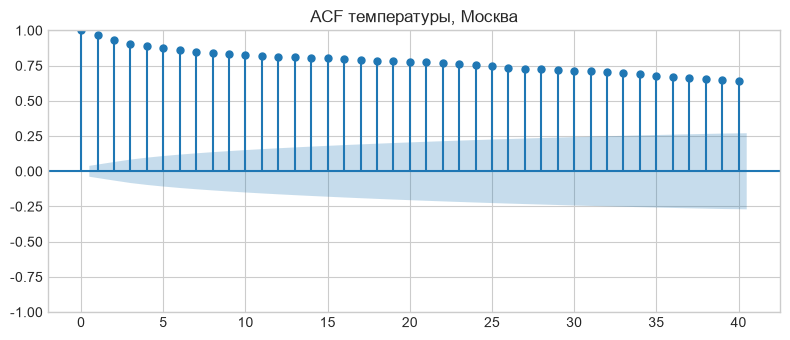

In [10]:
# автокорреляция температуры, чтобы выбрать лаги
acf_rows = []
for city in CITIES:
    y = daily.loc[daily["city"] == city, "temp"].dropna()
    values = acf(y, nlags=365, fft=True)
    acf_rows.append({
        "город": city,
        "лаг 1": round(float(values[1]), 3),
        "лаг 7": round(float(values[7]), 3),
        "лаг 30": round(float(values[30]), 3),
        "лаг 365": round(float(values[365]), 3),
    })
print(pd.DataFrame(acf_rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.5))
y = daily.loc[daily["city"] == "Москва", "temp"].dropna()
plot_acf(y, lags=40, ax=ax, title="ACF температуры, Москва")
plt.tight_layout()
plt.show()


Автокорреляция на коротких лагах высокая, 0.96-0.99 на первом и 0.84-0.94 на седьмом. На лагах 30 и 365 она остаётся около 0.69-0.81, и это уже годовой ход температуры. Поэтому в прогноз берём температуру вчера, неделю и месяц назад, скользящие среднее и разброс за 7 и 30 дней и норму календарного дня. Неделя примерно равна времени жизни одного циклона или антициклона, а 30 дней совпадают с горизонтом прогноза.

Скорость изменения температуры считаем как разность соседних дней, ускорение как разность скоростей, а темп давления как его суточную разность. Из календаря берём синус и косинус дня года и месяца, день недели, день месяца, месяц, сезон и год, а час после перехода к суткам представлен размахом дня и проекцией суточного хода. Ещё в признаки входит максимальный ветер за сутки.


In [11]:
def prepare_city(part):
    g = part.sort_index().copy()
    g["doy"] = g.index.dayofyear
    # 29 февраля относим к 365 дню, чтобы нашлась норма
    g.loc[g["doy"] == 366, "doy"] = 365
    g["month"] = g.index.month
    g["dow"] = g.index.dayofweek
    g["dom"] = g.index.day
    g["year"] = g.index.year
    # 0 зима, 1 весна, 2 лето, 3 осень
    g["season"] = (g["month"] % 12) // 3
    # норму дня считаем только по 2019-2023, проверка в неё не попадает
    train = g.index.year <= 2023
    norm = g.loc[train].groupby("doy")["temp"].mean()
    g["norm"] = g["doy"].map(norm)
    g["anom"] = g["temp"] - g["norm"]
    g["anom7"] = g["anom"].rolling(7, min_periods=3).mean()
    g["anom30"] = g["anom"].rolling(30, min_periods=10).mean()
    g["std7"] = g["temp"].rolling(7, min_periods=3).std()
    g["std30"] = g["temp"].rolling(30, min_periods=10).std()
    g["dtemp"] = g["temp"].diff()
    g["d2temp"] = g["dtemp"].diff()
    g["dpress"] = g["press"].diff()
    g["sin_doy"] = np.sin(2 * np.pi * g["doy"] / 365)
    g["cos_doy"] = np.cos(2 * np.pi * g["doy"] / 365)
    g["sin_month"] = np.sin(2 * np.pi * g["month"] / 12)
    g["cos_month"] = np.cos(2 * np.pi * g["month"] / 12)
    g["temp_l1"] = g["temp"].shift(1)
    g["temp_l7"] = g["temp"].shift(7)
    g["temp_l30"] = g["temp"].shift(30)
    return g

prepared = {city: prepare_city(daily.loc[daily["city"] == city]) for city in CITIES}
FEATS = [
    "temp_l1", "temp_l7", "temp_l30",
    "anom", "anom7", "anom30", "std7", "std30",
    "hum", "prec", "wind", "wind_max",
    "dpress", "dtemp", "d2temp",
    "sin_doy", "cos_doy", "sin_month", "cos_month",
    "diurnal_sin", "diurnal_cos",
    "trange", "dow", "dom", "month", "season", "year",
]
print("столбцы прогноза", ", ".join(FEATS))
print("норма дня года считается по 2019-2023")


столбцы прогноза temp_l1, temp_l7, temp_l30, anom, anom7, anom30, std7, std30, hum, prec, wind, wind_max, dpress, dtemp, d2temp, sin_doy, cos_doy, sin_month, cos_month, diurnal_sin, diurnal_cos, trange, dow, dom, month, season, year
норма дня года считается по 2019-2023


In [12]:
# окна по 30 суток для классификации и для PCA
def windows_of(g):
    g = g.sort_index()
    cols = CHANNELS
    values = g[cols].to_numpy(dtype=float)
    starts = np.arange(0, len(g) - WINDOW + 1, STRIDE)
    packed = np.stack([values[s:s + WINDOW] for s in starts])
    ends = g.index[starts + WINDOW - 1]
    return packed, ends

# случайные короткие фильтры, ядро центрируем, уровень канала храним отдельно
N_KERNELS = 40
KLEN = 9
kernel_specs = []
for channel in range(len(CHANNELS)):
    for _ in range(N_KERNELS):
        weight = RNG.normal(size=KLEN)
        weight = weight - weight.mean()
        bias = float(RNG.uniform(-1, 1))
        dilation = int(RNG.integers(1, 3))
        kernel_specs.append((channel, weight, bias, dilation))

def rocket_matrix(packed):
    blocks = []
    n = packed.shape[0]
    for channel, weight, bias, dilation in kernel_specs:
        series = packed[:, :, channel]
        length = WINDOW - (KLEN - 1) * dilation
        acc = np.zeros((n, length))
        for j, wj in enumerate(weight):
            acc += wj * series[:, j * dilation:j * dilation + length]
        acc = acc + bias
        blocks.append((acc > 0).mean(axis=1))
        blocks.append(acc.max(axis=1))
    level = packed.mean(axis=1)
    scale = packed.std(axis=1)
    return np.column_stack(blocks + [level, scale])

def named_matrix(packed):
    temp = packed[:, :, 0]
    hum = packed[:, :, 1]
    prec = packed[:, :, 2]
    wind = packed[:, :, 3]
    return np.column_stack([
        temp.mean(1), temp.std(1), temp.min(1), temp.max(1),
        hum.mean(1), prec.sum(1), (prec > 0.1).sum(1),  # сутки мокрые, если осадков больше 0.1 мм
        wind.mean(1), packed[:, :, 4].max(1),
    ])

def calendar_block(ends):
    month = ends.month.to_numpy()
    season = (month % 12) // 3
    return np.column_stack([
        np.sin(2 * np.pi * month / 12),
        np.cos(2 * np.pi * month / 12),
        ends.dayofweek.to_numpy(),
        ends.day.to_numpy(),
        month,
        season,
        ends.year.to_numpy(),
    ])

NAMED = [
    "temp среднее", "temp std", "temp min", "temp max",
    "hum среднее", "prec сумма", "дни с осадками",
    "wind среднее", "порыв max",
    "sin месяца", "cos месяца", "день недели", "день месяца", "месяц", "сезон", "год",
]

feat_parts = []
name_parts = []
end_parts = []
city_parts = []
for city in CITIES:
    packed, ends = windows_of(prepared[city])
    feat_parts.append(rocket_matrix(packed))
    name_parts.append(np.hstack([named_matrix(packed), calendar_block(ends)]))
    end_parts.append(ends)
    city_parts.append(np.array([city] * len(ends)))

X_model = np.vstack(feat_parts)
X_named = np.vstack(name_parts)
ends = pd.DatetimeIndex(np.concatenate(end_parts))
window_city = np.concatenate(city_parts)
window_climate = np.array([CLIMATE[c] for c in window_city])
print("окон", len(ends), "длина", WINDOW, "шаг", STRIDE, "фильтров на канал", N_KERNELS)
print("признаков фильтра", X_model.shape[1], "именованных", X_named.shape[1])
# рабочая матрица, фильтры плюс именованные статистики окна
X_model = np.hstack([X_model, X_named])


окон 2172 длина 30 шаг 7 фильтров на канал 40
признаков фильтра 410 именованных 16


доля дисперсии, две оси: 0.329, 0.150


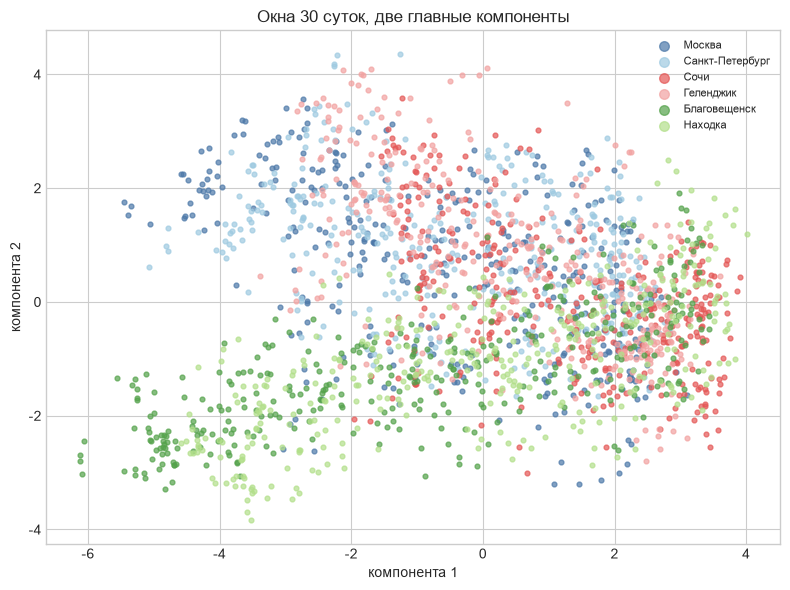

In [13]:
# PCA по именованным статистикам окна, цветом отмечен город
# шкалу и компоненты учим по окнам до 2024
train_mask = ends.year <= 2023
scaler_named = StandardScaler().fit(X_named[train_mask])
pca = PCA(n_components=2, random_state=0)
xy = pca.fit_transform(scaler_named.transform(X_named))
print(f"доля дисперсии, две оси: {pca.explained_variance_ratio_[0]:.3f}, {pca.explained_variance_ratio_[1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
palette = {
    "Москва": "#4c78a8",
    "Санкт-Петербург": "#9ecae1",
    "Сочи": "#e45756",
    "Геленджик": "#f2a2a1",
    "Благовещенск": "#54a24b",
    "Находка": "#b2df8a",
}
for city in CITIES:
    mask = window_city == city
    ax.scatter(xy[mask, 0], xy[mask, 1], s=12, alpha=0.7, label=city, color=palette[city])
ax.set_title("Окна 30 суток, две главные компоненты")
ax.set_xlabel("компонента 1")
ax.set_ylabel("компонента 2")
ax.legend(loc="best", fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()


Две главные компоненты объясняют 0.329 и 0.150 дисперсии статистик окна. Окна одного климата лежат рядом, но облака заметно пересекаются, так что простой границы между климатами нет.

Задачу усложняют две вещи. Летом города похожи по температуре, а внутри каждой пары климат общий, и различие держится на мелочах вроде числа дождливых дней. ARIMA здесь не подходит, на 30 точках она не видит годового хода, и её коэффициенты плохо отличают климаты. Ближайший сосед по сырым суткам ошибается, когда похожая погода сдвинута на пару дней, а LSTM на двух тысячах окон легко переобучается и плохо объясняется синоптику.

Поэтому берём классификатор в духе ROCKET. Случайные короткие фильтры проходят по ряду, и с каждого сохраняем долю положительных откликов и максимум. К ним добавляем средний уровень каждого канала, чтобы модель видела, зима сейчас или лето, и именованные статистики окна, минимум и максимум температуры, сумму осадков, число дождливых дней и календарь. Поверх обучаем гребневый классификатор на окнах длиной 30 суток, учим на окнах с концом в 2019-2023, штраф подбираем по 2024, а 2025 оставляем для проверки.

Для сравнения ту же задачу решаем только по именованным статистикам, без фильтров. Давление в классификатор не берём, его средний уровень повторяет высоту станции над морем.


 штраф  accuracy, 2024
   0.1           0.846
   1.0           0.849
  10.0           0.846
 100.0           0.833
штраф с 2024 1.0
              модель  accuracy  F1 macro  F1 weighted  ROC-AUC ovr
фильтры и статистики     0.748     0.749        0.749        0.910
     статистики окна     0.770     0.770        0.770        0.931
              модель           класс  precision  recall    F1  окон
фильтры и статистики       умеренный      0.837   0.726 0.778   106
фильтры и статистики    черноморский      0.765   0.708 0.735   106
фильтры и статистики дальневосточный      0.672   0.811 0.735   106
     статистики окна       умеренный      0.934   0.670 0.780   106
     статистики окна    черноморский      0.701   0.906 0.790   106
     статистики окна дальневосточный      0.743   0.736 0.739   106


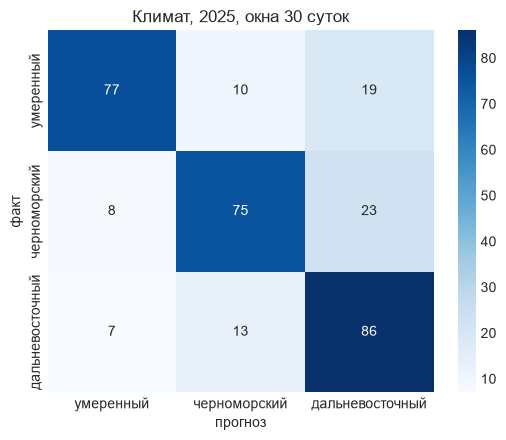

In [14]:
# штраф подбираем по 2024, окна 2025 в подбор не смотрим
def fit_climate(features, alpha):
    scaler = StandardScaler().fit(features[train_mask])
    model = RidgeClassifier(alpha=alpha).fit(scaler.transform(features[train_mask]), window_climate[train_mask])
    return scaler, model

val_mask = ends.year == 2024
test_mask = ends.year == 2025
alpha_rows = []
best_alpha = None
best_val = -1
for alpha in (0.1, 1.0, 10.0, 100.0):
    scaler, model = fit_climate(X_model, alpha)
    pred_val = model.predict(scaler.transform(X_model[val_mask]))
    acc = accuracy_score(window_climate[val_mask], pred_val)
    alpha_rows.append({"штраф": alpha, "accuracy, 2024": round(float(acc), 3)})
    if acc > best_val:
        best_val = acc
        best_alpha = alpha
print(pd.DataFrame(alpha_rows).to_string(index=False))
print("штраф с 2024", best_alpha)

rocket_scaler, rocket_model = fit_climate(X_model, best_alpha)
named_scaler, named_model = fit_climate(X_named, 1.0)

def report_split(name, model, scaler, features, mask):
    pred = model.predict(scaler.transform(features[mask]))
    true = window_climate[mask]
    labels = CLIM_ORDER
    precision, recall, f1, support = precision_recall_fscore_support(true, pred, labels=labels, zero_division=0)
    rows = []
    for i, label in enumerate(labels):
        rows.append({
            "модель": name,
            "класс": label,
            "precision": round(float(precision[i]), 3),
            "recall": round(float(recall[i]), 3),
            "F1": round(float(f1[i]), 3),
            "окон": int(support[i]),
        })
    # у гребня нет вероятностей, для ROC-AUC переводим отступы в доли
    scores = model.decision_function(scaler.transform(features[mask]))
    shifted = scores - scores.max(axis=1, keepdims=True)
    proba = np.exp(shifted)
    proba = proba / proba.sum(axis=1, keepdims=True)
    auc = roc_auc_score(
        true, proba, labels=list(model.classes_), multi_class="ovr", average="macro"
    )
    summary = {
        "модель": name,
        "accuracy": round(float(accuracy_score(true, pred)), 3),
        "F1 macro": round(float(f1_score(true, pred, average="macro")), 3),
        "F1 weighted": round(float(f1_score(true, pred, average="weighted")), 3),
        "ROC-AUC ovr": round(float(auc), 3),
    }
    return pred, true, pd.DataFrame(rows), summary

pred_test, true_test, by_class, summary_rocket = report_split("фильтры и статистики", rocket_model, rocket_scaler, X_model, test_mask)
_, _, by_class_named, summary_named = report_split("статистики окна", named_model, named_scaler, X_named, test_mask)
print(pd.DataFrame([summary_rocket, summary_named]).to_string(index=False))
print(pd.concat([by_class, by_class_named], ignore_index=True).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
matrix = confusion_matrix(true_test, pred_test, labels=CLIM_ORDER)
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=CLIM_ORDER, yticklabels=CLIM_ORDER, ax=ax)
ax.set_xlabel("прогноз")
ax.set_ylabel("факт")
ax.set_title("Климат, 2025, окна 30 суток")
plt.tight_layout()
plt.show()


accuracy по городу, 2025: 0.582
                 Москва  Санкт-Петербург  Сочи  Геленджик  Благовещенск  Находка
Москва               32                2     4          2            12        1
Санкт-Петербург      22               14     0          5             9        3
Сочи                  1                0    42          0             3        7
Геленджик            10                1    10         27             3        2
Благовещенск          5                1     5          3            32        7
Находка               0                1     7          1             6       38


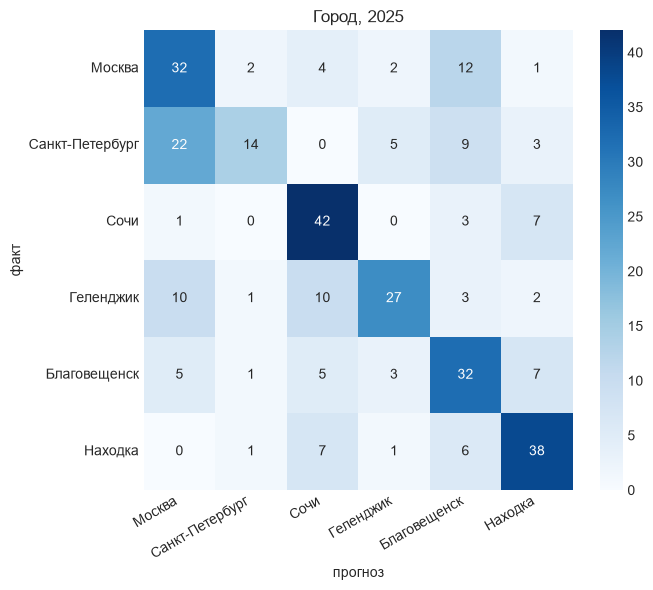

In [15]:
# тот же классификатор с городом вместо климата, чтобы увидеть путаницу внутри пары
city_scaler = StandardScaler().fit(X_model[train_mask])
city_model = RidgeClassifier(alpha=best_alpha).fit(
    city_scaler.transform(X_model[train_mask]), window_city[train_mask]
)
city_pred = city_model.predict(city_scaler.transform(X_model[test_mask]))
city_true = window_city[test_mask]
print(f"accuracy по городу, 2025: {accuracy_score(city_true, city_pred):.3f}")
city_matrix = confusion_matrix(city_true, city_pred, labels=CITIES)
print(pd.DataFrame(city_matrix, index=CITIES, columns=CITIES).to_string())
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(city_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=CITIES, yticklabels=CITIES, ax=ax)
ax.set_xlabel("прогноз")
ax.set_ylabel("факт")
ax.set_title("Город, 2025")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


 месяц  окон  accuracy
     1    30     0.900
     2    24     0.917
     3    24     0.750
     4    30     0.667
     5    24     0.625
     6    24     0.667
     7    30     0.633
     8    24     0.458
     9    24     0.792
    10    30     0.867
    11    24     0.833
    12    30     0.833
 год  окон  accuracy
2021   312     0.801
2022   312     0.849
2023   312     0.862
2024   312     0.885
2025   318     0.802


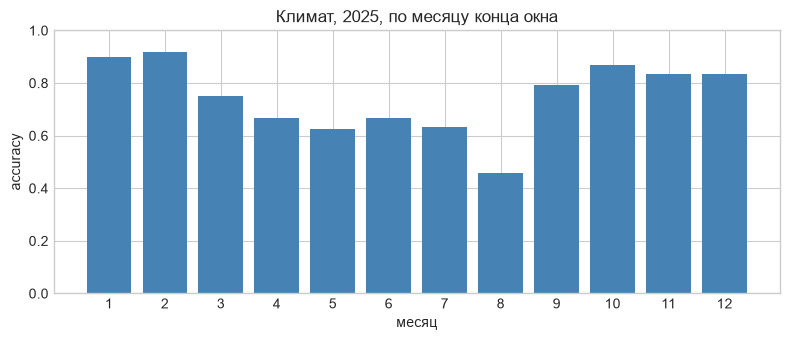

сезон  окон  accuracy
 зима    84     0.881
весна    78     0.679
 лето    78     0.590
осень    78     0.833


In [16]:
# качество по месяцу конца окна и по году
month_rows = []
for month in range(1, 13):
    mask = test_mask & (ends.month == month)
    acc = accuracy_score(window_climate[mask], rocket_model.predict(rocket_scaler.transform(X_model[mask])))
    month_rows.append({"месяц": month, "окон": int(mask.sum()), "accuracy": round(float(acc), 3)})
month_tbl = pd.DataFrame(month_rows)
print(month_tbl.to_string(index=False))

year_rows = []
# год, по которому считаем долю верных, из обучения убираем
for year in (2021, 2022, 2023, 2024, 2025):
    fit_mask = ends.year != year
    scaler = StandardScaler().fit(X_model[fit_mask])
    model = RidgeClassifier(alpha=best_alpha).fit(scaler.transform(X_model[fit_mask]), window_climate[fit_mask])
    mask = ends.year == year
    pred = model.predict(scaler.transform(X_model[mask]))
    year_rows.append({
        "год": year,
        "окон": int(mask.sum()),
        "accuracy": round(float(accuracy_score(window_climate[mask], pred)), 3),
    })
print(pd.DataFrame(year_rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(month_tbl["месяц"], month_tbl["accuracy"], color="steelblue")
ax.set_ylim(0, 1)
ax.set_xlabel("месяц")
ax.set_ylabel("accuracy")
ax.set_title("Климат, 2025, по месяцу конца окна")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

season_name = {0: "зима", 1: "весна", 2: "лето", 3: "осень"}
season_of = ends.month.map(lambda m: (int(m) % 12) // 3)
season_rows = []
for code, title in season_name.items():
    mask = test_mask & (season_of == code)
    acc = accuracy_score(window_climate[mask], rocket_model.predict(rocket_scaler.transform(X_model[mask])))
    season_rows.append({"сезон": title, "окон": int(mask.sum()), "accuracy": round(float(acc), 3)})
print(pd.DataFrame(season_rows).to_string(index=False))


       признак  падение accuracy
      temp min             0.228
    sin месяца             0.157
  temp среднее             0.155
    cos месяца             0.148
      temp max             0.125
  wind среднее             0.121
дни с осадками             0.114
   hum среднее             0.038
    prec сумма             0.035
      temp std             0.017
         месяц             0.003
   день месяца             0.002
   день недели             0.000
           год             0.000
     порыв max            -0.001
         сезон            -0.004


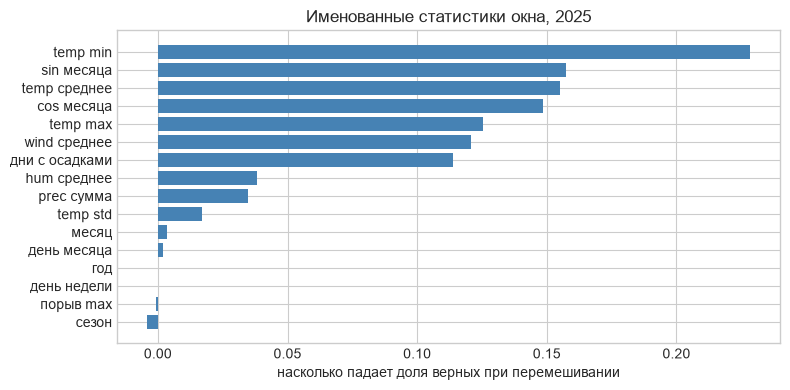

In [17]:
# важность считаем по именованным статистикам, у случайных фильтров нет физического смысла
perm = permutation_importance(
    named_model,
    named_scaler.transform(X_named[test_mask]),
    window_climate[test_mask],
    n_repeats=10,
    random_state=0,
    scoring="accuracy",
)
imp = (
    pd.Series(perm.importances_mean, index=NAMED)
    .sort_values(ascending=False)
    .rename("падение accuracy")
    .rename_axis("признак")
    .reset_index()
)
print(imp.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
imp_sorted = imp.sort_values("падение accuracy")
ax.barh(imp_sorted["признак"], imp_sorted["падение accuracy"], color="steelblue")
ax.set_xlabel("насколько падает доля верных при перемешивании")
ax.set_title("Именованные статистики окна, 2025")
plt.tight_layout()
plt.show()


На 2025 году связка фильтров и статистик даёт accuracy 0.748, F1 macro 0.749, F1 weighted 0.749 и ROC-AUC 0.910 при штрафе 1.0. Одни статистики окна дают чуть больше, accuracy 0.770 и ROC-AUC 0.931, так что фильтры по форме ряда точности не добавляют. Рабочей оставляем связку, в ней классификатор опирается на сам ход ряда, а статистики окна служат ориентиром.

Лучше всего климат узнаётся зимой, 0.881, затем осенью, 0.833, весной, 0.679, и хуже всего летом, 0.590. По месяцам разброс от 0.900 в январе до 0.458 в августе, когда температура у городов сходится. Если по очереди убирать из обучения один год, accuracy на нём держится от 0.801 до 0.885 для 2021-2024 и 0.802 для 2025, то есть от года к году модель устойчива.

Города различить труднее, accuracy 0.582. Чаще всего путаются Санкт-Петербург и Москва, 22 окна из 53 Санкт-Петербурга названы Москвой, а Геленджик по 10 раз путают с Сочи и с Москвой. Лучше всего узнаются Сочи и Находка, 42 и 38 окон из 53.

Сильнее всего на точность влияют минимальная температура окна, 0.228, синус месяца, 0.157, и средняя температура, 0.155. Синус месяца работает в паре с температурой и подсказывает, насколько холодно для этого времени года. День недели, год и сезон почти ничего не дают, в одну дату они у всех городов одинаковые.


In [18]:
# прогноз температуры на горизонтах 1, 7, 14, 30
# норма дня, инерция сегодняшней температуры, гребень на аномалии, бустинг на тех же столбцах

def horizon_frame(g, horizon):
    target_index = g.index.to_series().shift(-horizon)
    frame = g[FEATS].copy()
    frame["y"] = g["temp"].shift(-horizon)
    frame["ynorm"] = g["norm"].shift(-horizon)
    frame["pers"] = g["temp"]
    frame["today"] = g["temp"]
    frame["tyear"] = target_index.dt.year
    return frame.dropna()

def point_scores(y, pred, today):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    today = np.asarray(today, dtype=float)
    err = y - pred
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    wape = float(np.sum(np.abs(err)) / np.sum(np.abs(y)) * 100)
    # MAPE считаем, когда теплее 5 или холоднее -5, около нуля процент раздувается
    big = np.abs(y) >= 5
    mape = float(np.mean(np.abs(err[big]) / np.abs(y[big])) * 100) if big.any() else np.nan
    # знак изменения от сегодня, нулевой сдвиг тоже считаем исходом
    dy = np.sign(y - today)
    dp = np.sign(pred - today)
    direction = float((dy == dp).mean())
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "WAPE": wape, "направление": direction}

HORIZONS = [1, 7, 14, 30]
choice_rows = []
test_rows = []
fitted_ridge = {}
test_pack = {}

for city in CITIES:
    g = prepared[city]
    for horizon in HORIZONS:
        frame = horizon_frame(g, horizon)
        cols = FEATS
        # делим по году целевого дня, чтобы горизонт 30 не перенёс проверку в обучение
        tr = frame["tyear"] <= 2023
        va = frame["tyear"] == 2024
        te = frame["tyear"] == 2025
        # учим отклонение от нормы целевого дня и потом прибавляем норму обратно
        y_tr = frame.loc[tr, "y"] - frame.loc[tr, "ynorm"]
        ridge = Ridge(alpha=1.0).fit(frame.loc[tr, cols], y_tr)
        boost = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.08, max_iter=120, random_state=0
        ).fit(frame.loc[tr, cols], y_tr)
        fitted_ridge[(city, horizon)] = (ridge, frame, cols)

        def pack(index, pred):
            return point_scores(frame.loc[index, "y"], pred, frame.loc[index, "today"])

        options = {
            "норма": (frame["ynorm"], frame["ynorm"]),
            "инерция": (frame["pers"], frame["pers"]),
            "гребень": (
                frame["ynorm"] + ridge.predict(frame[cols]),
                frame["ynorm"] + ridge.predict(frame[cols]),
            ),
            "бустинг": (
                frame["ynorm"] + boost.predict(frame[cols]),
                frame["ynorm"] + boost.predict(frame[cols]),
            ),
        }
        val_mae = {}
        for name, (pred_all, _) in options.items():
            val_mae[name] = mean_absolute_error(frame.loc[va, "y"], pred_all.loc[va])
        winner = min(val_mae, key=val_mae.get)
        choice_rows.append({
            "город": city,
            "горизонт": horizon,
            "выбрано": winner,
            "MAE 2024 норма": round(val_mae["норма"], 3),
            "MAE 2024 инерция": round(val_mae["инерция"], 3),
            "MAE 2024 гребень": round(val_mae["гребень"], 3),
            "MAE 2024 бустинг": round(val_mae["бустинг"], 3),
        })
        pred_te = options[winner][0].loc[te]
        scores = point_scores(frame.loc[te, "y"], pred_te, frame.loc[te, "today"])
        scores.update({"город": city, "горизонт": horizon, "модель": winner})
        test_rows.append(scores)
        test_pack[(city, horizon)] = {
            "y": frame.loc[te, "y"],
            "pred": pred_te,
            "today": frame.loc[te, "today"],
            "index": frame.loc[te].index,
        }

choice = pd.DataFrame(choice_rows)
test_metrics = pd.DataFrame(test_rows)
print("выбор по 2024")
print(choice.to_string(index=False))
show = test_metrics[["город", "горизонт", "модель", "MAE", "RMSE", "MAPE", "WAPE", "направление"]].copy()
for col in ["MAE", "RMSE", "MAPE", "WAPE", "направление"]:
    show[col] = show[col].round(3)
print("проверка, 2025")
print(show.to_string(index=False))


выбор по 2024
          город  горизонт выбрано  MAE 2024 норма  MAE 2024 инерция  MAE 2024 гребень  MAE 2024 бустинг
         Москва         1 гребень           3.761             2.092             1.864             1.915
         Москва         7   норма           3.761             4.435             3.780             3.928
         Москва        14   норма           3.761             5.334             3.937             4.017
         Москва        30   норма           3.761             6.585             4.062             3.889
Санкт-Петербург         1 гребень           3.807             1.938             1.719             1.900
Санкт-Петербург         7   норма           3.807             4.460             3.948             3.948
Санкт-Петербург        14   норма           3.807             4.945             4.059             4.026
Санкт-Петербург        30   норма           3.807             5.708             3.982             4.105
           Сочи         1 гребень           2.500 

По 2024 на один день вперёд у всех городов лучше всего гребневая регрессия на отклонении от нормы, она обходит и вчерашнюю температуру, и норму. Начиная с недели у пяти городов выигрывает норма календарного дня, у Геленджика гребень держится до 7 дней, а на 30 дней норма лучше везде. Инерция на месяц ошибается сильнее, MAE от 4.350 в Сочи до 7.675 в Благовещенске против 2.415-3.807 у нормы.

На 2025 году прогноз на сутки даёт MAE от 1.158 в Сочи до 1.713 в Благовещенске, а прогноз на месяц по норме от 2.387 в Находке до 3.923 в Москве. Где выбрана норма, MAE на горизонтах 7, 14 и 30 совпадает, потому что норма от горизонта не зависит, а целевые дни те же. Направление изменения норма на месяц угадывает в 80-93% случаев, сезонный ход сам показывает, будет теплее или холоднее. MAPE считаем только по дням, где модуль температуры не меньше 5 градусов, иначе деление на число около нуля раздувает процент. Даже так у Москвы на месяц MAPE 33.6% и WAPE 40.4%, поэтому для температуры нагляднее MAE в градусах. Все пять метрик выведены для каждого города и каждого горизонта от 1 до 30 суток.

На коротком шаге архитектура у всех одна, гребневая регрессия, но коэффициенты у каждого города свои, потому что связь температуры с влажностью и давлением в климатах разная. На месяц у всех побеждает своя норма дня. ARIMA с пошаговым прогнозом на 30 дней не берём, у неё копится ошибка и нет годового хода, а одна модель на шесть городов не подходит, январь в Благовещенске и в Сочи отличается на 28 градусов.


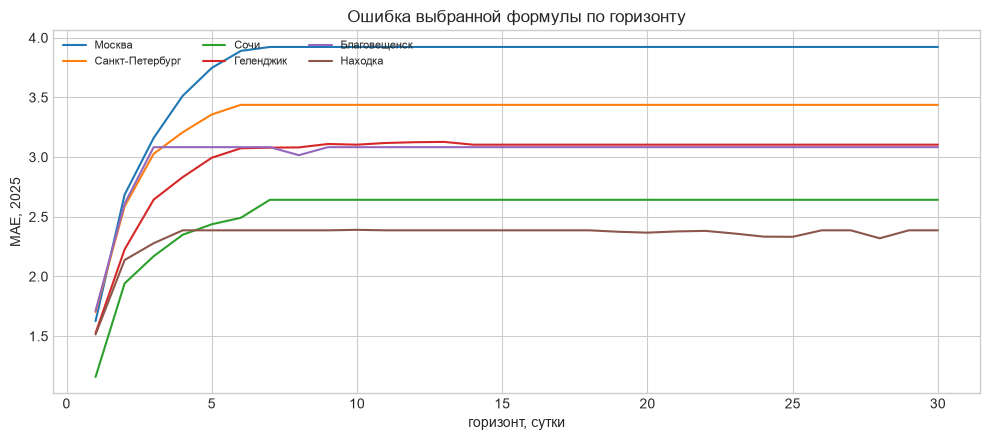

MAE
город     Москва  Санкт-Петербург   Сочи  Геленджик  Благовещенск  Находка
горизонт                                                                  
1          1.626            1.702  1.158      1.526         1.713    1.514
2          2.685            2.587  1.942      2.226         2.610    2.138
3          3.160            3.028  2.170      2.644         3.083    2.278
4          3.513            3.208  2.349      2.832         3.083    2.387
5          3.747            3.357  2.437      2.995         3.083    2.387
6          3.890            3.438  2.491      3.074         3.083    2.387
7          3.923            3.438  2.642      3.079         3.083    2.387
8          3.923            3.438  2.642      3.081         3.016    2.387
9          3.923            3.438  2.642      3.110         3.083    2.387
10         3.923            3.438  2.642      3.104         3.083    2.391
11         3.923            3.438  2.642      3.118         3.083    2.387
12         3.923     

In [19]:
# кривая MAE по горизонту, норма и инерция и выбранная формула
# на промежуточных горизонтах выбираем между нормой, инерцией и гребнем, бустинг считаем только на 1, 7, 14, 30

curve_rows = []
path_models = {}
for city in CITIES:
    g = prepared[city]
    for horizon in range(1, 31):
        frame = horizon_frame(g, horizon)
        # делим по году целевого дня, чтобы горизонт 30 не перенёс проверку в обучение
        tr = frame["tyear"] <= 2023
        va = frame["tyear"] == 2024
        te = frame["tyear"] == 2025
        ridge = Ridge(alpha=1.0).fit(frame.loc[tr, FEATS], frame.loc[tr, "y"] - frame.loc[tr, "ynorm"])
        pred_ridge = frame["ynorm"] + pd.Series(ridge.predict(frame[FEATS]), index=frame.index)
        options = {
            "норма": frame["ynorm"],
            "инерция": frame["pers"],
            "гребень": pred_ridge,
        }
        if horizon in HORIZONS:
            # на этих горизонтах модель уже выбрана выше
            winner = choice.loc[(choice["город"] == city) & (choice["горизонт"] == horizon), "выбрано"].iloc[0]
            if winner == "бустинг":
                boost = HistGradientBoostingRegressor(
                    max_depth=3, learning_rate=0.08, max_iter=120, random_state=0
                ).fit(frame.loc[tr, FEATS], frame.loc[tr, "y"] - frame.loc[tr, "ynorm"])
                options["бустинг"] = frame["ynorm"] + pd.Series(boost.predict(frame[FEATS]), index=frame.index)
        else:
            val_mae = {name: mean_absolute_error(frame.loc[va, "y"], pred.loc[va]) for name, pred in options.items()}
            winner = min(val_mae, key=val_mae.get)
        chosen = options[winner].loc[te]
        scores = point_scores(frame.loc[te, "y"], chosen, frame.loc[te, "today"])
        curve_rows.append({
            "город": city,
            "горизонт": horizon,
            "модель": winner,
            "MAE": scores["MAE"],
            "RMSE": scores["RMSE"],
            "MAPE": scores["MAPE"],
            "WAPE": scores["WAPE"],
            "направление": scores["направление"],
            "MAE норма": mean_absolute_error(frame.loc[te, "y"], frame.loc[te, "ynorm"]),
            "MAE инерция": mean_absolute_error(frame.loc[te, "y"], frame.loc[te, "pers"]),
        })
        path_models[(city, horizon)] = (winner, options[winner], frame)

curve = pd.DataFrame(curve_rows)
fig, ax = plt.subplots(figsize=(10, 4.5))
for city in CITIES:
    part = curve.loc[curve["город"] == city]
    ax.plot(part["горизонт"], part["MAE"], linewidth=1.5, label=city)
ax.set_xlabel("горизонт, сутки")
ax.set_ylabel("MAE, 2025")
ax.set_title("Ошибка выбранной формулы по горизонту")
ax.legend(loc="upper left", ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

full_metrics = pd.DataFrame(curve_rows)
for metric in ["MAE", "RMSE", "MAPE", "WAPE", "направление"]:
    pivot = (
        full_metrics.pivot(index="горизонт", columns="город", values=metric)
        .reindex(columns=CITIES)
        .round(3)
    )
    print(metric)
    print(pivot.to_string())


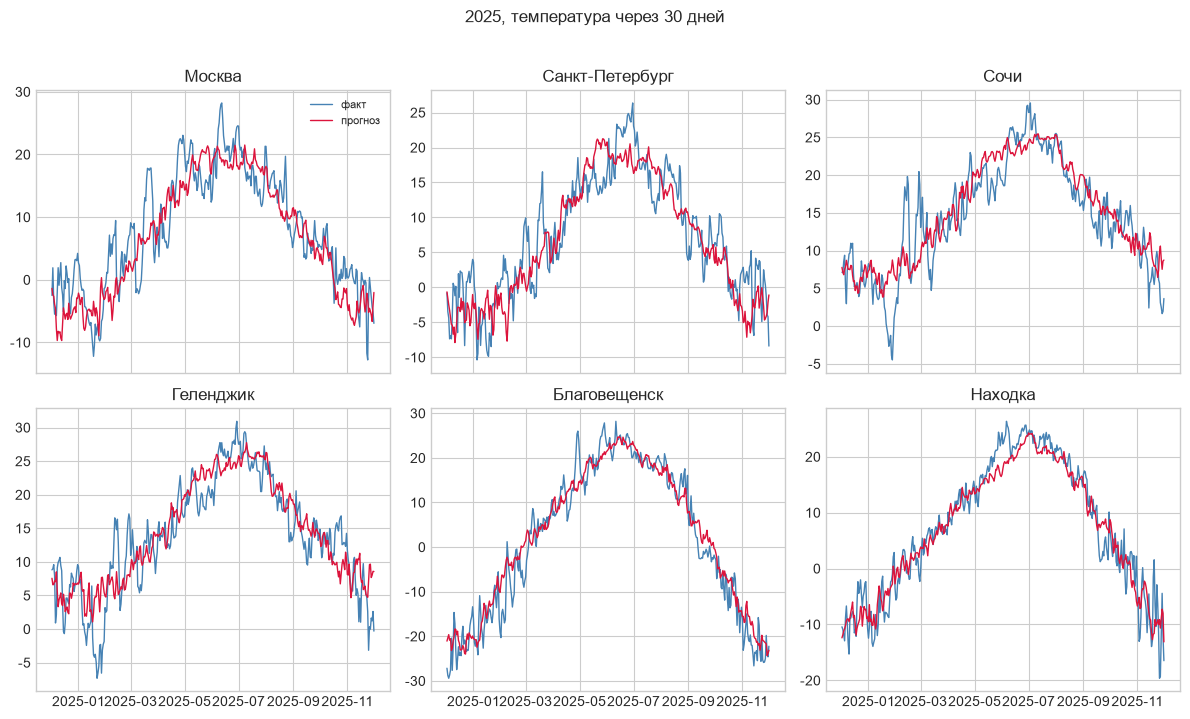

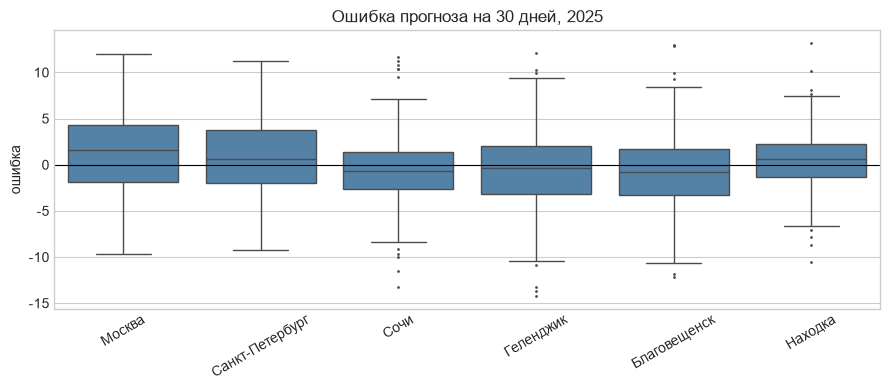

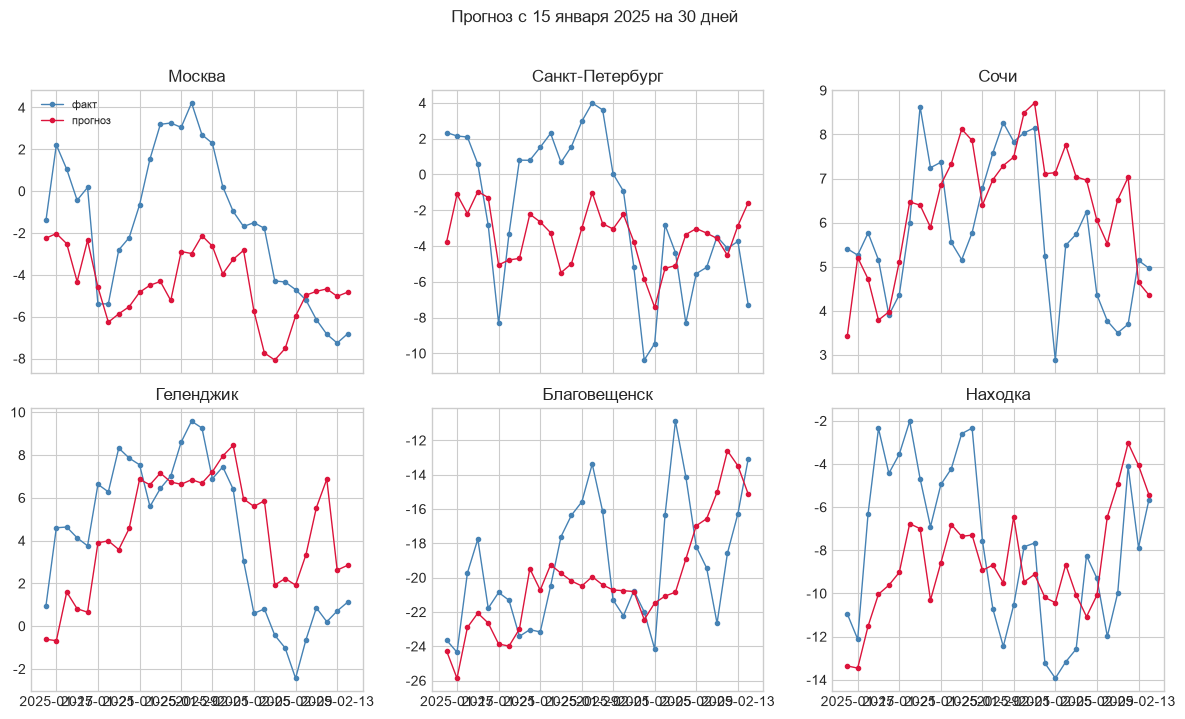

In [20]:
# 2025, факт и прогноз на 30 дней, и ящик ошибок
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)
for ax, city in zip(axes.ravel(), CITIES):
    pack = test_pack[(city, 30)]
    ax.plot(pack["index"], pack["y"], color="steelblue", linewidth=1.0, label="факт")
    ax.plot(pack["index"], pack["pred"], color="crimson", linewidth=1.0, label="прогноз")
    ax.set_title(city)
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.suptitle("2025, температура через 30 дней", y=1.02)
plt.tight_layout()
plt.show()

err_rows = []
for city in CITIES:
    pack = test_pack[(city, 30)]
    err_rows.append(pd.DataFrame({"город": city, "ошибка": pack["y"].to_numpy() - pack["pred"].to_numpy()}))
err = pd.concat(err_rows, ignore_index=True)
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=err, x="город", y="ошибка", order=CITIES, ax=ax, color="steelblue", fliersize=1)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Ошибка прогноза на 30 дней, 2025")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# месяц вперёд с 15 января 2025
issue = pd.Timestamp("2025-01-15")
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)
for ax, city in zip(axes.ravel(), CITIES):
    actual = []
    forecast = []
    dates = []
    for horizon in range(1, 31):
        winner, pred_all, frame = path_models[(city, horizon)]
        actual.append(float(frame.loc[issue, "y"]))
        forecast.append(float(pred_all.loc[issue]))
        dates.append(issue + pd.Timedelta(days=horizon))
    ax.plot(dates, actual, color="steelblue", marker="o", markersize=3, linewidth=1.0, label="факт")
    ax.plot(dates, forecast, color="crimson", marker="o", markersize=3, linewidth=1.0, label="прогноз")
    ax.set_title(city)
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.suptitle("Прогноз с 15 января 2025 на 30 дней", y=1.02)
plt.tight_layout()
plt.show()


In [21]:
# остатки выбранной модели на 2025, горизонты 1 и 30
resid_rows = []
for city in CITIES:
    for horizon in (1, 30):
        pack = test_pack[(city, horizon)]
        resid = (pack["y"] - pack["pred"]).dropna()
        pred = pack["pred"].loc[resid.index]
        shapiro_p = float(stats.shapiro(resid).pvalue)
        lb = acorr_ljungbox(resid, lags=[1, 7], return_df=True)
        # уайт смотрит, меняется ли разброс ошибки вместе с прогнозом
        exog = sm.add_constant(np.asarray(pred, dtype=float))
        white_p = float(het_white(np.asarray(resid, dtype=float), exog)[1])
        resid_rows.append({
            "город": city,
            "горизонт": horizon,
            "Шапиро p": round(shapiro_p, 4),
            "Льюнг-Бокс p, лаг 1": round(float(lb.loc[1, "lb_pvalue"]), 4),
            "Льюнг-Бокс p, лаг 7": round(float(lb.loc[7, "lb_pvalue"]), 4),
            "Уайт p": round(white_p, 4),
        })
print(pd.DataFrame(resid_rows).to_string(index=False))


          город  горизонт  Шапиро p  Льюнг-Бокс p, лаг 1  Льюнг-Бокс p, лаг 7  Уайт p
         Москва         1    0.0007               0.0048               0.0091  0.0776
         Москва        30    0.0686               0.0000               0.0000  0.0041
Санкт-Петербург         1    0.7272               0.0881               0.0588  0.0001
Санкт-Петербург        30    0.0278               0.0000               0.0000  0.0000
           Сочи         1    0.0016               0.0000               0.0001  0.0042
           Сочи        30    0.0000               0.0000               0.0000  0.0002
      Геленджик         1    0.0067               0.0066               0.0404  0.0001
      Геленджик        30    0.0277               0.0000               0.0000  0.0000
   Благовещенск         1    0.0023               0.2006               0.0077  0.0003
   Благовещенск        30    0.1152               0.0000               0.0000  0.0000
        Находка         1    0.0000               0.35

Остатки прогноза на сутки нормальны только в Санкт-Петербурге, тест Шапиро-Уилка даёт p 0.7272, у остальных p не выше 0.0067. На месяц ближе к нормальным остатки Москвы и Благовещенска, p 0.0686 и 0.1152. Льюнг-Бокс на горизонте 30 суток у всех даёт p меньше 0.0001 на лагах 1 и 7, ошибки соседних дней связаны, потому что тёплая или холодная аномалия держится несколько суток. На сутках лаг 1 не значим у Санкт-Петербурга, Благовещенска и Находки, p 0.0881, 0.2006 и 0.3599. Тест Уайта на месяц везде ниже 0.005, разброс ошибки меняется вместе с прогнозом, а на сутках ровный разброс только у Москвы, p 0.0776.


In [22]:
# по последним 30 суткам называем климат и берём прогнозную формулу этого климата
# модели климата учим на обоих городах пары, выбор формулы снова по 2024

def apply_formula(row, winner, ridge):
    if winner == "норма":
        return float(row["ynorm"])
    if winner == "инерция":
        return float(row["pers"])
    x = row[FEATS].to_frame().T
    return float(row["ynorm"] + ridge.predict(x)[0])

def fit_climate_horizon(cities, horizon):
    frames = []
    for city in cities:
        frame = horizon_frame(prepared[city], horizon).copy()
        frame["city"] = city
        frames.append(frame)
    frame = pd.concat(frames)
    tr = frame["tyear"] <= 2023
    va = frame["tyear"] == 2024
    y_anom = frame.loc[tr, "y"] - frame.loc[tr, "ynorm"]
    ridge = Ridge(alpha=1.0).fit(frame.loc[tr, FEATS], y_anom)
    pred_ridge = frame["ynorm"].to_numpy() + ridge.predict(frame[FEATS])
    y_va = frame.loc[va, "y"].to_numpy()
    val_mae = {
        "норма": mean_absolute_error(y_va, frame.loc[va, "ynorm"]),
        "инерция": mean_absolute_error(y_va, frame.loc[va, "pers"]),
        "гребень": mean_absolute_error(y_va, pred_ridge[va.to_numpy()]),
    }
    winner = min(val_mae, key=val_mae.get)
    return winner, ridge, round(float(val_mae[winner]), 3)

climate_choice = []
climate_models = {}
for climate in CLIM_ORDER:
    members = [city for city in CITIES if CLIMATE[city] == climate]
    for horizon in (1, 7, 14, 30):
        winner, ridge, val_mae = fit_climate_horizon(members, horizon)
        climate_models[(climate, horizon)] = (winner, ridge)
        climate_choice.append({
            "климат": climate,
            "горизонт": horizon,
            "выбрано": winner,
            "MAE 2024": val_mae,
        })
print(pd.DataFrame(climate_choice).to_string(index=False))

# окно до 15 января 2025 называет климат, дальше 30 дней считаем формулой этого климата
issue = pd.Timestamp("2025-01-15")
pipe_rows = []
for city in CITIES:
    history = prepared[city].loc[:issue].tail(WINDOW)
    packed = history[CHANNELS].to_numpy(dtype=float)[None, :, :]
    features = np.hstack([rocket_matrix(packed), named_matrix(packed), calendar_block(pd.DatetimeIndex([history.index.max()]))])
    predicted = rocket_model.predict(rocket_scaler.transform(features))[0]
    true_climate = CLIMATE[city]
    abs_right = []
    abs_used = []
    for horizon in (1, 7, 14, 30):
        row = horizon_frame(prepared[city], horizon).loc[issue]
        actual = float(row["y"])
        winner_right, ridge_right = climate_models[(true_climate, horizon)]
        winner_used, ridge_used = climate_models[(predicted, horizon)]
        abs_right.append(abs(actual - apply_formula(row, winner_right, ridge_right)))
        abs_used.append(abs(actual - apply_formula(row, winner_used, ridge_used)))
    pipe_rows.append({
        "город": city,
        "факт": true_climate,
        "прогноз климата": predicted,
        "совпало": int(predicted == true_climate),
        "MAE своего климата": round(float(np.mean(abs_right)), 3),
        "MAE названного климата": round(float(np.mean(abs_used)), 3),
    })
print("выпуск 15 января 2025, среднее |ошибки| по горизонтам 1, 7, 14, 30")
print(pd.DataFrame(pipe_rows).to_string(index=False))

# ошибка, если подставить формулу чужого климата
cross_rows = []
for city in CITIES:
    for climate in CLIM_ORDER:
        errors = []
        for horizon in (1, 7, 14, 30):
            row = horizon_frame(prepared[city], horizon).loc[issue]
            winner, ridge = climate_models[(climate, horizon)]
            errors.append(abs(float(row["y"]) - apply_formula(row, winner, ridge)))
        cross_rows.append({
            "город": city,
            "модель климата": climate,
            "средняя |ошибка|": round(float(np.mean(errors)), 3),
        })
cross = pd.DataFrame(cross_rows).pivot(index="город", columns="модель климата", values="средняя |ошибка|")
cross = cross.reindex(index=CITIES, columns=CLIM_ORDER)
print("та же дата, чужая формула климата")
print(cross.to_string())

# здесь уже все окна с концом в 2025
city_frames = {
    (city, horizon): horizon_frame(prepared[city], horizon)
    for city in CITIES
    for horizon in (1, 30)
}
used = {1: [], 30: []}
right = {1: [], 30: []}
wrong_only = {1: [], 30: []}
n_windows = 0
n_miss = 0
for city, end, predicted in zip(window_city[test_mask], ends[test_mask], pred_test):
    n_windows += 1
    true_climate = CLIMATE[city]
    missed = predicted != true_climate
    if missed:
        n_miss += 1
    for horizon in (1, 30):
        frame = city_frames[(city, horizon)]
        if end not in frame.index:
            continue
        row = frame.loc[end]
        actual = float(row["y"])
        winner_right, ridge_right = climate_models[(true_climate, horizon)]
        winner_used, ridge_used = climate_models[(predicted, horizon)]
        err_right = abs(actual - apply_formula(row, winner_right, ridge_right))
        err_used = abs(actual - apply_formula(row, winner_used, ridge_used))
        right[horizon].append(err_right)
        used[horizon].append(err_used)
        if missed:
            wrong_only[horizon].append(err_used - err_right)

pipe_all = []
for horizon in (1, 30):
    pipe_all.append({
        "горизонт": horizon,
        "окон": len(used[horizon]),
        "MAE своего климата": round(float(np.mean(right[horizon])), 3),
        "MAE названного климата": round(float(np.mean(used[horizon])), 3),
        "ошибок климата": n_miss,
        "доля ошибок": round(n_miss / n_windows, 3),
        "прибавка MAE на ошибках": round(float(np.mean(wrong_only[horizon])), 3) if wrong_only[horizon] else 0.0,
    })
print("все окна 2025")
print(pd.DataFrame(pipe_all).to_string(index=False))


         климат  горизонт выбрано  MAE 2024
      умеренный         1 гребень     1.791
      умеренный         7   норма     3.784
      умеренный        14   норма     3.784
      умеренный        30   норма     3.784
   черноморский         1 гребень     1.403
   черноморский         7 гребень     2.802
   черноморский        14   норма     2.840
   черноморский        30   норма     2.840
дальневосточный         1 гребень     1.690
дальневосточный         7   норма     2.532
дальневосточный        14   норма     2.532
дальневосточный        30   норма     2.532
выпуск 15 января 2025, среднее |ошибки| по горизонтам 1, 7, 14, 30
          город            факт прогноз климата  совпало  MAE своего климата  MAE названного климата
         Москва       умеренный       умеренный        1               2.492                   2.492
Санкт-Петербург       умеренный       умеренный        1               4.790                   4.790
           Сочи    черноморский    черноморский        1  

та же дата, чужая формула климата
модель климата   умеренный  черноморский  дальневосточный
город                                                    
Москва               2.492         2.600            2.632
Санкт-Петербург      4.790         4.772            4.972
Сочи                 0.851         0.821            0.958
Геленджик            1.764         1.860            1.824
Благовещенск         2.576         3.301            2.425
Находка              2.276         2.495            2.169


все окна 2025
 горизонт  окон  MAE своего климата  MAE названного климата  ошибок климата  доля ошибок  прибавка MAE на ошибках
        1   312               1.526                   1.533              80        0.252                    0.025
       30   288               3.101                   3.101              80        0.252                    0.000


В выпуске от 15 января 2025 все шесть окон отнесены к своему климату. По всем окнам 2025 года климат назван неверно в 80 окнах из 318, доля ошибок 0.252. На сутки вперёд такая ошибка почти ничего не стоит, MAE с верным климатом 1.526, с названным 1.533, а на ошибочных окнах прибавка 0.025 градуса. На месяц обе MAE равны 3.101, потому что у всех климатов на этом горизонте выбрана норма, а её считаем по самому городу. Значит, двухэтапная схема влияет только на короткий прогноз, а месячный от ошибки классификатора не зависит.


In [23]:
# сводка проверки
summary_rows = []
for city in CITIES:
    row = {"город": city, "климат": CLIMATE[city]}
    for horizon in (1, 30):
        part = test_metrics.loc[(test_metrics["город"] == city) & (test_metrics["горизонт"] == horizon)].iloc[0]
        row[f"модель h={horizon}"] = part["модель"]
        row[f"MAE h={horizon}"] = round(float(part["MAE"]), 3)
    summary_rows.append(row)
print(pd.DataFrame(summary_rows).to_string(index=False))
print(f"классификация климата, 2025, accuracy: {summary_rocket['accuracy']}")
print(f"классификация климата, 2025, F1 macro: {summary_rocket['F1 macro']}")


          город          климат модель h=1  MAE h=1 модель h=30  MAE h=30
         Москва       умеренный    гребень    1.626       норма     3.923
Санкт-Петербург       умеренный    гребень    1.702       норма     3.438
           Сочи    черноморский    гребень    1.158       норма     2.642
      Геленджик    черноморский    гребень    1.526       норма     3.104
   Благовещенск дальневосточный    гребень    1.713       норма     3.083
        Находка дальневосточный    гребень    1.514       норма     2.387
классификация климата, 2025, accuracy: 0.748
классификация климата, 2025, F1 macro: 0.749


**Сводка.** Классификатор климата по окну в 30 суток на 2025 году даёт accuracy 0.748 и F1 macro 0.749, зимой 0.881 и летом 0.590. Температуру на сутки вперёд лучше всего прогнозирует гребневая регрессия, MAE от 1.158 до 1.713 градуса, а на месяц вперёд норма календарного дня, MAE от 2.387 до 3.923. Двухэтапный подход оправдан для короткого прогноза, а на месяц он совпадает с прогнозом по норме своего города, и ошибка классификации на нём не сказывается.
